# Microbiome-Based Disease Prediction: DeepPhylo vs. Random Forest

This notebook benchmarks a phylogeny-aware deep-learning model (**DeepPhylo**) against a
standard **Random Forest** baseline for predicting disease status from 16S microbiome
abundance profiles. It is organised into two independent analyses:

1. **Oral disease classification (Leave-One-Study-Out).** Using pooled oral samples from many
   public studies, we predict each disease vs. healthy controls (HC), always holding out one
   *entire study* for testing. This measures how well a model generalises **across studies**
   (different labs, protocols, and batch effects).

2. **Paired oral–gut projects (within-study 5-fold CV).** Using studies that sampled both oral
   and gut sites from the same cohorts, we predict disease vs. HC separately for each body site
   with stratified cross-validation, so we can compare how predictive each site is.

For both analyses, DeepPhylo and Random Forest are run on **identical data splits** and their
per-split AUC is compared.

> **Environment note.** The code expects a local `DeepPhylo` package, the microbiome `.biom`
> tables and metadata files, and a precomputed phylogenetic embedding on disk. The paths are
> specific to the original machine and would need to be adjusted to re-run elsewhere.

# Methods

## Microbiome datasets and study cohorts

Disease status was predicted from 16S rRNA gene amplicon microbiome profiles
assembled from multiple publicly available studies. Two complementary
collections were analysed. The first was a pooled **oral** collection, in which
samples from many independent studies were aggregated to enable cross-study
evaluation of disease-versus-healthy-control (HC) classification. The second was
a set of **paired oral–gut** projects, in which the oral and gut microbiota were
sampled from the same cohorts, allowing a within-study comparison of the
predictive value of each body site. For each collection, feature tables were
stored as BIOM-format operational taxonomic unit (OTU) count matrices with
accompanying sample metadata (body site, disease status, and study/BioProject
identifier).

## Quality control and feature filtering

Identical quality-control (QC) criteria were applied to both collections. First,
the feature table was restricted to samples present in the metadata, and empty
features and samples were removed. Rare OTUs, defined as those detected in 50 or
fewer samples, were discarded to reduce noise and dimensionality. Samples with a
sequencing depth below 1,000 total reads were removed as unreliable. After each
filtering step the table was re-checked for empty rows and columns, and the
metadata were re-synchronised to the surviving samples. Samples with a missing
disease label or a non-specific "Other" label were excluded so that every
retained sample carried a well-defined disease or HC status. Finally, per-sample
relative abundances were obtained by total-sum normalisation of the filtered
count table, and the resulting abundance matrix was aligned to a fixed,
phylogenetically ordered set of OTUs (see below).

## Phylogenetic feature representation

DeepPhylo exploits the evolutionary relationships among taxa. A cophenetic
(patristic) distance matrix encoding the pairwise phylogenetic tree distances
between OTUs was used to derive a phylogeny-informed taxa embedding. OTUs were
arranged in a fixed phylogenetic order so that evolutionarily related taxa occupy
neighbouring positions, allowing the abundance profile of each sample to be
treated as a one-dimensional signal. Both the ordered OTU list and the
precomputed phylogenetic embedding were shared across all experiments to ensure
that every model and data split used an identical feature representation.

## DeepPhylo model and training

The phylogeny-aware classifier (DeepPhylo) applies one-dimensional convolutional
filters across the phylogenetically ordered OTUs, so that each filter integrates
information from neighbouring (evolutionarily related) taxa. The network used a
hidden dimension of 80, a convolutional kernel of size 3, and a pooling kernel of
size 7, with rectified linear unit (ReLU) activations, and produced a single
sigmoid output representing the predicted disease probability.

Models were trained by minimising the binary cross-entropy loss using the AdamW
optimiser with a learning rate of 1×10⁻³ and a batch size of 32, for up to 100
epochs. Within every training set, 15% of the samples were held out as an
internal validation set, and early stopping was applied with a patience of 10
epochs; the weights from the epoch with the lowest validation loss were retained
for prediction. When class sizes permitted, the internal train/validation split
was stratified by label. A fixed random seed was used throughout to promote
reproducibility, and all models were trained on GPU when available.

## Random Forest baseline

As a baseline, a Random Forest classifier was trained on the same relative
abundance features. It comprised 100 trees with balanced class weights to
mitigate class imbalance, and used a fixed random seed. Critically, the Random
Forest and DeepPhylo models were trained and evaluated on **identical data
splits** in every experiment, so that their per-split performance is directly
comparable. Predicted disease probabilities were taken from the positive-class
output of the fitted forest.

## Evaluation design 1: cross-study generalisation (leave-one-study-out)

Cross-study generalisation was assessed on the oral collection using a
leave-one-study-out (LOSO) scheme, applied separately to each oral site
(saliva, tooth, tongue, and oral mucosa). Within each site, studies and diseases
were selected according to three criteria: (i) a study was retained only if it
contained both HC samples and at least one disease group; (ii) a study was
required to include more than 10 HC samples so that the control group was not
negligibly small; and (iii) a disease was analysed only if it was present in at
least two studies, which is the minimum required for LOSO (one study to train on
and one to hold out).

For each qualifying disease, every study was in turn held out entirely as the
test set while the model was trained on the remaining studies, framing the task
as the target disease versus HC. Because the held-out study contributes its own
laboratory- and protocol-specific batch effects, this design provides a strict
test of generalisation to unseen studies. Splits in which either the training or
test partition lacked both classes—for which the area under the receiver
operating characteristic curve (AUC) is undefined—were skipped. The test AUC was
recorded for every evaluable study, and results were aggregated per disease and
per site.

## Evaluation design 2: within-study cross-validation (paired oral–gut)

The paired oral–gut collection was used to compare the predictive value of the
oral and gut microbiomes within the same cohorts. Samples were grouped by
(project × body site × disease status), and only groups containing more than 10
samples were retained. A project was evaluated only if it contained all four
expected groups—both body sites, each with HC and disease samples—so that the
oral-versus-gut comparison was always made on the same cohort.

For each qualifying project, the task was defined as disease (any non-HC status)
versus HC and was evaluated **separately** for the gut and oral samples using
stratified five-fold cross-validation. Within each training fold, an internal
validation split (15%) was used for early stopping of DeepPhylo, exactly as in
the LOSO analysis. Projects or sites whose smaller class contained fewer samples
than the number of folds were skipped, as were individual folds whose test
partition did not contain both classes. Per-fold test AUC was recorded, and a
per-(project × site) summary (mean and standard deviation across folds) was
computed.

## Performance evaluation and model comparison

Classification performance was quantified throughout by the AUC, computed from
the predicted disease probabilities on each held-out partition. Because DeepPhylo
and Random Forest were evaluated on identical splits within both designs, the two
models could be compared directly at the level of the individual test study
(LOSO) or the individual fold, study, and body site (five-fold cross-validation),
with an AUC of 0.5 denoting chance-level performance. For the paired oral–gut
analysis, each project was additionally annotated with its associated disease
(the single non-HC status present in the project) to enable disease-level
comparison. Results were visualised as per-site and per-disease comparisons of
DeepPhylo versus Random Forest AUC, with paired points connected across models to
highlight per-study differences.

In [1]:
import sys
sys.path.insert(0, '/home/dongbiao/software/DeepPhylo')

import matplotlib as mpl
import os
import math
import biom
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from skbio import TreeNode

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

In [2]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

In [400]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from deepphylo.pre_dataset import set_seed, reducer, DeepPhyDataset
from deepphylo.model import DeepPhylo_classification

In [275]:
from itertools import product

In [380]:
import random
from math import comb
from itertools import combinations

In [399]:
from skbio import TreeNode

## Configuration and hyperparameters

All DeepPhylo settings live in one place so the rest of the notebook stays clean:

- **Model shape** — `DP_HIDDEN_SIZE`, a 1-D convolution kernel (`DP_KERNEL_CONV`) and a pooling
  kernel (`DP_KERNEL_POOL`). DeepPhylo treats the phylogenetically-ordered OTUs like a 1-D
  signal and slides filters over neighbouring (evolutionarily related) taxa.
- **Optimisation** — AdamW with learning rate `DP_LR`, batch size `DP_BATCH_SIZE`, up to
  `DP_EPOCHS` epochs, with **early stopping** after `DP_PATIENCE` epochs of no improvement.
  A fraction `DP_VAL_FRAC` of the training data is reserved as an internal validation set.

We also create the output directory and load the **cophenetic distance matrix** — the pairwise
patristic (tree) distances between OTUs — which encodes the phylogeny DeepPhylo uses to build
its taxa embedding.

## Training helpers

Two small utilities used throughout the notebook:

- **`train_deepphylo(...)`** — trains one binary DeepPhylo classifier. It wraps the abundance
  matrix and phylogenetic embedding in a `DeepPhyDataset`, trains with binary cross-entropy on
  the sigmoid output, and keeps the weights from the epoch with the lowest validation loss
  (early stopping).
- **`predict_proba(...)`** — runs a trained model in evaluation mode and returns the predicted
  disease probability for each test sample (used to compute AUC).

# Part 1 — Oral disease classification (Leave-One-Study-Out)

## Load the oral dataset and apply quality control

We load the oral `.biom` OTU table and its metadata, then apply standard microbiome QC:

- keep only samples that appear in the metadata;
- drop **rare OTUs** (present in ≤ 50 samples) to cut noise and dimensionality;
- drop **low-depth samples** (< 1,000 total reads), which are unreliable;
- remove any now-empty rows/columns and re-sync the metadata to the surviving samples.

In [290]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [370]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'sample_cr_mapping_rate', 'study_cr_mapping_rate',
       'Observed', 'Shannon', 'Simpson', 'InvSimpson', 'Chao1', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'age_cleaned', 'bmi_cleaned', 'age_cleaned_group', 'age_info_cleaned',
       'bmi_cleaned_group', 'sex_cleaned', 'platform_cleaned',
       'sequencing_region_cleaned', 'country_cleaned', 'continent_group',
       'site_cleaned', 'site_group_cleaned', 'disease_study_cleaned',
       'status_cleaned', 'asv_le_30', 'study_asv_lt30_high', 'chim_gt_25',
       'study_chim_gt25_high', 'sample_cr_mapping_low',
       'study_cr_mapping_low'],
      dtype='object')

In [281]:
metadata.status_cleaned.unique()

array(['Dental Caries', 'OSCC', 'HC', 'Gastroesophageal Reflux Disease',
       'IBD', 'Hypertension', nan, 'Other', 'Digestive Tract Cancer',
       'HIV', 'Diabetes', 'Clostridium Difficile Infection',
       'ICU discharge or on ICU day 10', 'ICU', 'Obesity', 'Asthma',
       'Periodontal Disease', 'Atopic Dermatitis',
       'Cardiovascular Disease', 'Chagas Disease', 'Head and Neck Cancer',
       'Oral Submucous Fibrosis', 'Oral Mucositis',
       'Oral Verrucous Hyperplasia', 'Preterm', 'Breast Cancer',
       'COVID-19', 'Prostate Cancer', 'Colorectal Cancer', 'Aphthous',
       'Oral Lichen Planus', 'Celiac Disease', 'Acute Myeloid Leukemia',
       'Lung Cancer', "Sjögren's Syndrome",
       'Helicobacter pylori Infection', 'Pancreatic Cancer',
       'Autoimmune Hepatitis', 'RA', 'Alcohol Use Disorder',
       'Esophageal Cancer', 'Hand, Foot and Mouth Disease',
       "Parkinson's Disease", '1-year COVID-19 convalescent',
       'COVID-19 discharge', 'Nonmalignant Breast Di

In [324]:
table.shape

(2667, 44380)

In [350]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
run_site = []
run_disease = []
run_test_study = []
for site in oral_sites:
    print(site)
    # Set of statuses present in each bioproject
    metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]
    status_per_proj = metadata.groupby("bioproject_id")["status_cleaned"].apply(set)
    
    # Condition study has both HC and at least one disease status
    cond_both = status_per_proj.apply(lambda s: ("HC" in s) and (len(s - {"HC"}) > 0))

    # Keep studies satisfying 
    keep_proj = status_per_proj.index[cond_both]
    metadata = metadata.loc[metadata.bioproject_id.isin(keep_proj)].copy()
    
    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    result = result.query('sample_id > 5')
    for s in result.status_cleaned.unique():
        if s == "HC":
            continue
        print(f"\n=== Processing: {s} ===")
        result_pick = result[result['status_cleaned'].isin(["HC", s])]
        study_status_num = result_pick.groupby('bioproject_id')['status_cleaned'].nunique()
        filtered_bioprojects = study_status_num[study_status_num == 2].index.tolist()
  
        if len(filtered_bioprojects) >= 2:
            result_pick = result_pick[result_pick['bioproject_id'].isin(filtered_bioprojects)]
            print(f"{len(filtered_bioprojects)} bioprojects with {result_pick.sample_id.sum()} samples")
            ### leave one study out
            for j in filtered_bioprojects:
                run_disease.append(s.replace(' ', '_'))
                run_site.append(site.replace(' ', '_'))
                run_test_study.append(j)
                train_study = result_pick[result_pick.bioproject_id != j]['bioproject_id'].unique()
                train_sid = metadata[metadata['bioproject_id'].isin(train_study)]['sample_id'].values
                test_sid = metadata[metadata.bioproject_id == j]['sample_id'].values

                train_biom = table.filter(train_sid, axis="sample", inplace=False)
                train_biom.remove_empty()
                fid = train_biom.ids(axis="observation")
                test_biom = table.filter(test_sid, axis="sample", inplace=False)
                test_biom.filter(fid, axis="observation")

                print(f"train table: {train_biom.shape}, test table: {test_biom.shape}")

                with biom.util.biom_open(f"data/lso_train_{site.replace(' ', '_')}_{s.replace(' ', '_')}_{j}.biom", 'w') as f:
                    train_biom.to_hdf5(f, 'example')
                with biom.util.biom_open(f"data/lso_test_{site.replace(' ', '_')}_{s.replace(' ', '_')}_{j}.biom", 'w') as f:
                    test_biom.to_hdf5(f, 'example')
        else:
            print(f"  Found only {len(filtered_bioprojects)} bioprojects with both statuses, skipping...")

saliva

=== Processing: Gastroesophageal Reflux Disease ===
3 bioprojects with 384 samples
train table: (903, 192), test table: (903, 192)
train table: (1339, 317), test table: (1339, 67)
train table: (1333, 259), test table: (1333, 125)

=== Processing: Hypertension ===
2 bioprojects with 102 samples
train table: (715, 57), test table: (715, 92)
train table: (877, 92), test table: (877, 57)

=== Processing: IBD ===
4 bioprojects with 317 samples
train table: (1013, 260), test table: (1013, 92)
train table: (1033, 133), test table: (1033, 219)
train table: (1308, 332), test table: (1308, 20)
train table: (1301, 331), test table: (1301, 21)

=== Processing: Digestive Tract Cancer ===
  Found only 1 bioprojects with both statuses, skipping...

=== Processing: HIV ===
4 bioprojects with 198 samples
train table: (721, 165), test table: (721, 33)
train table: (888, 182), test table: (888, 16)
train table: (840, 164), test table: (840, 34)
train table: (832, 83), test table: (832, 115)

=== 

In [351]:
run_info = pd.DataFrame({"site": run_site, "disease": run_disease, "study": run_test_study})

In [352]:
run_info.head()

,site,disease,study
0,saliva,Gastroesophageal_Reflux_Disease,PRJCA005537
1,saliva,Gastroesophageal_Reflux_Disease,PRJNA639327
2,saliva,Gastroesophageal_Reflux_Disease,PRJNA674379
3,saliva,Hypertension,PRJCA006963
4,saliva,Hypertension,PRJNA764503


In [353]:
run_info.to_csv("run_info.csv", index=None)

In [347]:
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata = metadata.set_index("sample_id")
metadata['group'] = [0 if i == "HC" else 1 for i in metadata.status_cleaned.values]
metadata.to_csv("meta.tsv", sep="\t")

## Compare DeepPhylo vs. Random Forest (per site)

For each oral site we plot every LOSO test-study AUC as a point, with the two models
side-by-side and a thin grey line connecting the *same study* across models. Diseases are
ordered by DeepPhylo's median AUC, short horizontal bars mark each model's mean, and the dashed
line at 0.5 marks chance. This makes it easy to see, disease by disease, whether the
phylogeny-aware model beats the Random Forest baseline.

DeepPhylo vs Random Forest -- LOSO (leave-one-study-out) AUC comparison.

This script has two parts:

  PART 1  -- Build the six summary tables the plot needs, straight from the
             raw per-sample prediction files:
                 run_info.csv                       -> which (site, disease, study) exist
                 result/predictions_deepphylo_*.csv -> DeepPhylo probabilities (Prob_1)
                 result/RF_results_lso.csv          -> RF probabilities (pred_prob)
                 meta_oral_gut.tsv                  -> TRUE case/control labels
             For every (site, disease, study) it computes
                 auc = roc_auc_score(y_true, y_score)
             and writes, per oral site:
                 <OUTPUT_DIR>/loso_auc_all_diseases_<token>.csv       (DeepPhylo)
                 <OUTPUT_DIR>/rf_loso_auc_all_diseases_<token>.csv    (RF)

  PART 2  -- The provided plotting code, unchanged, which reads those files.

WHY A METADATA FILE IS NEEDED
    AUC = area under the ROC curve of (true label, predicted score). The
    prediction files only contain the SCORE (Prob_1 / pred_prob), never the
    true label, so the true label has to come from the metadata. This is the
    only thing you must wire up -- see the CONFIG block right below.

/home/dongbiao/tmp/ipykernel_287247/580556739.py:40: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[write] saliva: DeepPhylo=47 rows, RF=47 rows
[write] tooth: DeepPhylo=9 rows, RF=9 rows


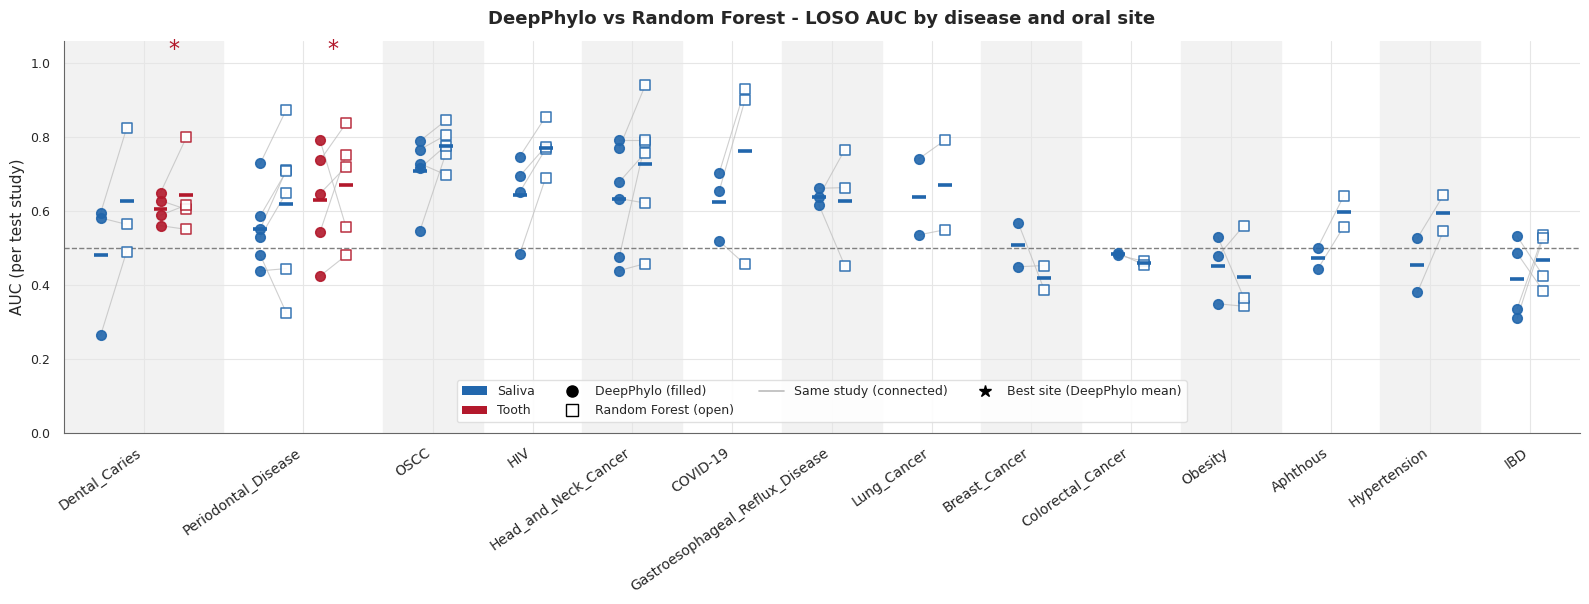

In [410]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC tables (kept in memory as dp_long / rf_long)
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info.csv"          # columns: site, disease, study
RESULT_DIR = "result"                # where the prediction csv files live
RF_FILE    = os.path.join(RESULT_DIR, "RF_results_lso.csv")
OUTPUT_DIR = "result"                # where the (optional) summary csv files go
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Site tokens to drop from the whole analysis (as they appear in run_info).
EXCLUDE_SITES = {"oral_mucosa"}

# Map plot display name -> the site token used in filenames / run_info / groups.
SITE_TOKENS = {
    "Saliva":      "saliva",
    "Tooth":       "tooth",
    "Oral mucosa": "oral_mucosa",
}
TOKEN_TO_DISPLAY = {v: k for k, v in SITE_TOKENS.items()}

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID / sampel_id
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = meta[META_LABEL_COL]
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]   # site/disease/study
run_info = run_info[~run_info["site"].isin(EXCLUDE_SITES)].copy()  # drop excluded sites
labels = load_labels()

# ---- DeepPhylo: one prediction file per (site, disease, study) --------------
dp_records = []
for _, r in run_info.iterrows():
    site, disease, study = str(r["site"]), str(r["disease"]), str(r["study"])
    path = os.path.join(
        RESULT_DIR, f"predictions_deepphylo_{site}_{disease}_{study}.csv"
    )
    if not os.path.exists(path):
        print(f"[DeepPhylo] missing, skipped: {path}")
        continue
    pred = pd.read_csv(path)                       # SampleID, Prob_1, Pred
    y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
    y_true = labels.reindex(y_score.index)
    dp_records.append(
        {"site": site, "disease": disease, "test_study": study,
         "auc": safe_auc(y_true, y_score)}
    )
dp_long = pd.DataFrame(dp_records)

# ---- Random Forest: a single file, split by the `group` column --------------
# group looks like "<site>_<disease>_<study>". We rebuild the expected group
# from run_info instead of splitting the string (disease names have underscores).
rf_raw = pd.read_csv(RF_FILE)                       # sampel_id, group, pred_prob
rf_raw["group"] = rf_raw["group"].astype(str)

rf_records = []
for _, r in run_info.iterrows():
    site, disease, study = str(r["site"]), str(r["disease"]), str(r["study"])
    group = f"{site}_{disease}_{study}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    y_score = sub.set_index(sub["sampel_id"].astype(str))["pred_prob"]
    y_true = labels.reindex(y_score.index)
    rf_records.append(
        {"site": site, "disease": disease, "test_study": study,
         "auc": safe_auc(y_true, y_score)}
    )
rf_long = pd.DataFrame(rf_records)

# ---- (Optional) also write per-site summary tables to disk ------------------
cols = ["disease", "test_study", "auc"]
for display, token in SITE_TOKENS.items():
    if token in EXCLUDE_SITES:
        continue
    (dp_long[dp_long["site"] == token][cols]
        .to_csv(os.path.join(OUTPUT_DIR, f"loso_auc_all_diseases_{token}.csv"),
                index=False))
    (rf_long[rf_long["site"] == token][cols]
        .to_csv(os.path.join(OUTPUT_DIR, f"rf_loso_auc_all_diseases_{token}.csv"),
                index=False))
    print(f"[write] {token}: "
          f"DeepPhylo={len(dp_long[dp_long['site'] == token])} rows, "
          f"RF={len(rf_long[rf_long['site'] == token])} rows")


# =============================================================================
# PART 2 -- plot, using the in-memory dp_long / rf_long from PART 1
# =============================================================================

SITE_COLORS = {'Saliva': '#2166AC',       # blue
               'Tooth': '#B2182B',        # red
               'Oral mucosa': '#1B7837'}  # green

MODEL_MARKERS = {'DeepPhylo': 'o', 'RF': 's'}

# Layout (in data units)
SITE_SLOT = 0.60      # width reserved for one site inside a disease group
GROUP_GAP = 0.40      # empty space between two disease groups
MODEL_OFFSET = 0.13   # +/- shift of the two models inside a site slot
MEAN_HALFWIDTH = 0.07

# Automatic figure sizing
INCHES_PER_UNIT = 0.95   # figure inches per data unit of x-axis
MIN_WIDTH, MAX_WIDTH = 8.0, 26.0
FIG_HEIGHT = 6.2

MARK_BEST_SITE = True     # star above the best site per disease (DeepPhylo mean)

# ---------------------------------- BUILD LONG TABLE FROM MEMORY (dp/rf_long) -
dp = dp_long.dropna(subset=['auc']).copy()
rf = rf_long.dropna(subset=['auc']).copy()
dp['model'] = 'DeepPhylo'
rf['model'] = 'RF'

data = pd.concat([dp, rf], ignore_index=True)
data['site'] = data['site'].map(TOKEN_TO_DISPLAY)   # token -> display name
data = data.dropna(subset=['site']).copy()          # drop unmapped / excluded sites

# Keep only diseases present for BOTH models within each site (mirrors original)
kept = []
for site_display, g in data.groupby('site'):
    shared = set(g[g.model == 'DeepPhylo']['disease']) & set(g[g.model == 'RF']['disease'])
    kept.append(g[g['disease'].isin(shared)])
data = pd.concat(kept, ignore_index=True)

# Display sites actually present, in the configured order
SITE_ORDER = [d for d in SITE_TOKENS if d in set(data['site'])]

# ----------------------------------------------------------- DISEASE ORDER ---
dp_all = data[data.model == 'DeepPhylo']
n_sites = dp_all.groupby('disease')['site'].nunique()
med_auc = dp_all.groupby('disease')['auc'].median()
order = (pd.DataFrame({'n_sites': n_sites, 'med': med_auc})
         .sort_values(['n_sites', 'med'], ascending=[False, False])
         .index.tolist())

# ------------------------------------------ ADAPTIVE X LAYOUT (VARIABLE WIDTH)
present_sites = {
    d: [s for s in SITE_ORDER
        if not data[(data.disease == d) & (data.site == s)].empty]
    for d in order
}

site_x = {}        # (disease, site) -> x centre of that site slot
tick_pos = []      # x centre of each disease group
band = []          # (left, right) of each disease band, for shading

cursor = 0.0
for d in order:
    k = len(present_sites[d])
    width = k * SITE_SLOT
    for j, s in enumerate(present_sites[d]):
        site_x[(d, s)] = cursor + (j + 0.5) * SITE_SLOT
    tick_pos.append(cursor + width / 2)
    band.append((cursor - GROUP_GAP / 2, cursor + width + GROUP_GAP / 2))
    cursor += width + GROUP_GAP

total_units = cursor - GROUP_GAP

# ------------------------------------------------------------------ PLOT -----
fig_width = float(np.clip(INCHES_PER_UNIT * total_units + 2.0, MIN_WIDTH, MAX_WIDTH))
fig, ax = plt.subplots(figsize=(fig_width, FIG_HEIGHT))

for i, (left, right) in enumerate(band):
    if i % 2 == 0:
        ax.axvspan(left, right, color='#F2F2F2', zorder=0)

for d in order:
    for s in present_sites[d]:
        d_site = data[(data.disease == d) & (data.site == s)]
        dp_s = d_site[d_site.model == 'DeepPhylo'].set_index('test_study')['auc']
        rf_s = d_site[d_site.model == 'RF'].set_index('test_study')['auc']
        xc = site_x[(d, s)]

        # Connect the two models for the same test study
        for study in dp_s.index.intersection(rf_s.index):
            ax.plot([xc - MODEL_OFFSET, xc + MODEL_OFFSET],
                    [dp_s[study], rf_s[study]],
                    color='#BBBBBB', lw=0.8, alpha=0.7, zorder=1)

        # Scatter + mean bar
        for model, vals, off in (('DeepPhylo', dp_s, -MODEL_OFFSET),
                                 ('RF', rf_s, +MODEL_OFFSET)):
            if len(vals) == 0:
                continue
            x = xc + off
            face = SITE_COLORS[s] if model == 'DeepPhylo' else 'white'
            ax.scatter(np.full(len(vals), x), vals.values,
                       marker=MODEL_MARKERS[model], s=48,
                       facecolors=face, edgecolors=SITE_COLORS[s],
                       linewidths=1.1, alpha=0.9, zorder=3)
            ax.hlines(vals.mean(), x - MEAN_HALFWIDTH, x + MEAN_HALFWIDTH,
                      colors=SITE_COLORS[s], linewidths=2.6, zorder=4)

    # Star the best-performing site for this disease (DeepPhylo mean AUC)
    if MARK_BEST_SITE and len(present_sites[d]) >= 2:
        means = (data[(data.disease == d) & (data.model == 'DeepPhylo')]
                 .groupby('site')['auc'].mean())
        best = means.idxmax()
        ax.text(site_x[(d, best)], 1.005, '*',
                ha='center', va='bottom', fontsize=16,
                color=SITE_COLORS[best], zorder=5)

# ------------------------------------------------------------------ AXES -----
ax.axhline(0.5, ls='--', c='grey', lw=1, zorder=2)
ax.set_ylabel('AUC (per test study)')
ax.set_ylim(0, 1.06)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlim(-GROUP_GAP / 2, total_units + GROUP_GAP / 2)

ax.set_xticks(tick_pos)
tick_fs = float(np.clip(140.0 / max(len(order), 1), 7, 11))
ax.set_xticklabels(order, rotation=35, ha='right', fontsize=tick_fs)
ax.spines[['top', 'right']].set_visible(False)

# ---------------------------------------------------------------- LEGEND -----
# Only show colours for sites that are actually present.
handles = [Patch(facecolor=SITE_COLORS[s], edgecolor='none', label=s) for s in SITE_ORDER]
handles += [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None',
                  markersize=8, label='DeepPhylo (filled)'),
    mlines.Line2D([], [], marker='s', linestyle='None', markersize=8,
                  markerfacecolor='white', markeredgecolor='black',
                  label='Random Forest (open)'),
    mlines.Line2D([], [], color='#BBBBBB', linestyle='-', linewidth=1.2,
                  label='Same study (connected)'),
]
if MARK_BEST_SITE:
    handles.append(mlines.Line2D([], [], color='black', marker='*', linestyle='None',
                                 markersize=9, label='Best site (DeepPhylo mean)'))

ax.legend(handles=handles, loc='lower center', ncol=4, fontsize=9,
          frameon=True, framealpha=0.9, edgecolor='#DDDDDD',
          bbox_to_anchor=(0.5, 0.01))

ax.set_title('DeepPhylo vs Random Forest - LOSO AUC by disease and oral site',
             fontsize=13, fontweight='bold', pad=12)
fig.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loso_deepphylo_vs_rf.png"), dpi=200, bbox_inches="tight")
plt.show()

### Oral and gut paired project

# Part 2 — Paired oral–gut projects

These studies sampled **both oral and gut sites from the same cohorts**, which lets us ask a
different question: for a given disease, is the oral or the gut microbiome more predictive?  
same OTUs

## Load the paired dataset and apply quality control

We load the paired `.biom` table and metadata and apply the same QC as before (drop rare OTUs,
drop low-depth samples, re-sync metadata), then remove samples with missing or `"Other"` labels.

In [398]:
table = biom.load_table("../../data/oral-gut-pair-v2-qc/biom_oral_gut_pair_v2_qc.biom")
metadata = pd.read_csv("../../data/oral-gut-pair-v2-qc/metadata_oral_gut_pair_v2_merge_qc.csv", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [402]:
# tree = TreeNode.read("/beegfs/dongbiao/greengene2/2024.09.phylogeny_backbone.nwk")
# fid = table.ids(axis="observation")
# tree = tree.shear(fid)
# tree.prune()
# dm   = tree.tip_tip_distances()
# C_df = pd.DataFrame(dm.data, index=dm.ids, columns=dm.ids)
# C_df.to_csv("data/cophenetic_matrix.csv")

In [386]:
table

2203 x 6563 <class 'biom.table.Table'> with 721536 nonzero entries (4% dense)

In [387]:
metadata = metadata.loc[metadata.status_cleaned.notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [388]:
metadata = metadata.set_index("sample_id")
metadata['group'] = [0 if i == "HC" else 1 for i in metadata.status_cleaned.values]
metadata.to_csv("meta_oral_gut.tsv", sep="\t")

In [357]:
metadata.head()

,pair_id,pair_time_point,pair_bioproject,pair_type,pair_sample_number,pair_subject_number,bioproject,sample_id,subject_id,age,...,sex_cleaned,platform_cleaned,sequencing_region_cleaned,country_cleaned,continent_group,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,is_time_series_cleaned
0,PRJEB1799_FS_10,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261872,FS_10,35.0,...,M,Illumina GAIIx,V2,United States,North America,feces,Gut,No,HC,no
1,PRJEB1799_FS_37,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261877,FS_37,33.0,...,M,Illumina GAIIx,V2,United States,North America,feces,Gut,No,HC,no
2,PRJEB1799_FS_10,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261880,FS_10,35.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no
3,PRJEB1799_FS_28,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261883,FS_28,46.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no
4,PRJEB1799_FS_141,NaN,PRJEB1799,single pair,169,169,PRJEB1799,ERR261887,FS_141,29.0,...,M,Illumina GAIIx,V2,United States,North America,tongue,Oral,No,HC,no


In [358]:
metadata.status_cleaned.unique()

array(['HC', 'Atopic Dermatitis', 'Cardiovascular Disease', 'Lung Cancer',
       'Preterm', 'Periodontal Disease', "Parkinson's Disease",
       'COVID-19 discharge', '1-year COVID-19 convalescent', 'COVID-19',
       "Alzheimer's Disease", 'Axial Spondyloarthritis', 'HIV', 'ICU',
       'ICU discharge or on ICU day 10', 'Hypertension'], dtype=object)

## Keep sufficiently-sized study × site × status groups

We count samples per (project, body site, disease status) and keep only groups with **more than
10 samples**, then collect the surviving project IDs. Later we require a project to have all
**four** expected groups present (both sites × both HC/disease) before evaluating it, so the
oral-vs-gut comparison is always made on the same cohort.

In [359]:
md_summary = pd.DataFrame(metadata.groupby(["pair_bioproject", "site_group_cleaned", "status_cleaned"])["sample_id"].count())
md_summary = md_summary.loc[md_summary.sample_id > 10]

In [360]:
project_id = np.unique([i[0] for i in md_summary.index.values])

In [366]:
N_SPLITS = 5
run_site = []
run_study = []
run_fold = []
for i in project_id:
    if md_summary.loc[i].shape[0] != 4:
        continue
    for site in ["Gut", "Oral"]:
        metadata_pick = metadata.loc[metadata.pair_bioproject == i].copy()
        metadata_pick = metadata_pick.loc[metadata_pick.site_group_cleaned == site].copy()
        metadata_pick["label"] = (metadata_pick["status_cleaned"] != "HC").astype(int)
        sid = metadata_pick.sample_id.values
        y   = metadata_pick["label"].values.astype(int)
        cls_count = np.bincount(y, minlength=2)
        if len(np.unique(y)) < 2 or cls_count.min() < N_SPLITS:
            print(f"[SKIP] study {i} / {site}: "
                  f"n={len(y)} pos={int(y.sum())} cannot run {N_SPLITS}-fold stratified CV")
            all_records.append({'study': i, 'site': site, 'fold': np.nan,
                                'n_train': np.nan, 'n_test': len(y),
                                'n_test_pos': int(y.sum()), 'auc': np.nan})
            continue
        skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
        for fold, (tr_idx, te_idx) in enumerate(skf.split(sid, y), start=1):
            train_sid,  Y_all  = sid[tr_idx], y[tr_idx].astype(np.float32)
            test_sid, Y_test = sid[te_idx], y[te_idx].astype(np.float32)
            # Test fold not both-class -> AUC undefined, record NaN
            if len(np.unique(Y_test)) < 2:
                print(f"  study {i}/{site} fold{fold}: test fold not both-class, skip")
                continue
            run_site.append(site)
            run_study.append(i)
            run_fold.append(fold)
            train_biom = table.filter(train_sid, axis="sample", inplace=False)
            train_biom.remove_empty()
            fid = train_biom.ids(axis="observation")
            test_biom = table.filter(test_sid, axis="sample", inplace=False)
            test_biom.filter(fid, axis="observation")

            print(f"train table: {train_biom.shape}, test table: {test_biom.shape}")

            with biom.util.biom_open(f"data/five_fold_train_{site.replace(' ', '_')}_{i}_{fold}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/five_fold_test_{site.replace(' ', '_')}_{i}_{fold}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')

train table: (1013, 52), test table: (1013, 13)
train table: (1019, 52), test table: (1019, 13)
train table: (998, 52), test table: (998, 13)
train table: (1024, 52), test table: (1024, 13)
train table: (1028, 52), test table: (1028, 13)
train table: (660, 52), test table: (660, 13)
train table: (684, 52), test table: (684, 13)
train table: (665, 52), test table: (665, 13)
train table: (686, 52), test table: (686, 13)
train table: (685, 52), test table: (685, 13)
[SKIP] study PRJEB11425 / Gut: n=71 pos=71 cannot run 5-fold stratified CV
[SKIP] study PRJEB11425 / Oral: n=71 pos=71 cannot run 5-fold stratified CV
train table: (1231, 123), test table: (1231, 31)
train table: (1227, 123), test table: (1227, 31)
train table: (1210, 123), test table: (1210, 31)
train table: (1223, 123), test table: (1223, 31)
train table: (1216, 124), test table: (1216, 30)
train table: (983, 123), test table: (983, 31)
train table: (987, 123), test table: (987, 31)
train table: (968, 123), test table: (968,

  study PRJDB9093/Gut fold5: n_train=52 n_test=13 pos=11 AUC=1.000


  study PRJDB9093/Oral fold1: n_train=52 n_test=13 pos=10 AUC=1.000


  study PRJDB9093/Oral fold2: n_train=52 n_test=13 pos=10 AUC=0.900


  study PRJDB9093/Oral fold3: n_train=52 n_test=13 pos=10 AUC=0.833


...

  study PRJNA767939/Oral fold1: n_train=28 n_test=8 pos=5 AUC=1.000


  study PRJNA767939/Oral fold2: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold3: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold4: n_train=29 n_test=7 pos=4 AUC=1.000


  study PRJNA767939/Oral fold5: n_train=29 n_test=7 pos=4 AUC=1.000
          study  site     mean       std  count
0     PRJDB9093   Gut  0.99334  0.014892      5
1     PRJDB9093  Oral  0.93756  0.071354      5
2    PRJEB23853   Gut  0.96894  0.033297      5
3    PRJEB23853  Oral  1.00000  0.000000      5
4    PRJEB25569   Gut  0.97500  0.034233      5
5    PRJEB25569  Oral  0.79354  0.158282      5
6   PRJNA742875   Gut  0.67544  0.093584      5
7   PRJNA742875  Oral  0.64044  0.138718      5
8   PRJNA764503   Gut  0.41786  0.275087      5
9   PRJNA764503  Oral  0.40120  0.130912      5
10  PRJNA767939   Gut  0.93334  0.108652      5
11  PRJNA767939  Oral  1.00000  0.000000      5


In [367]:
run_info = pd.DataFrame({"site": run_site, "fold": run_fold, "study": run_study})
run_info.to_csv("run_info_oral_gut.csv", index=None)

## Final comparison: per-disease boxplots

One panel per disease. Within each panel the x-axis is the study and the boxes are grouped by
**site × model** (Gut/Oral × DeepPhylo/RF): colour encodes the site and shade encodes the model
(dark = DeepPhylo, light = RF). Individual fold AUCs are overlaid as jittered points, and the
dashed line marks chance (0.5). This lets us read off, for each disease and study, whether
DeepPhylo improves on Random Forest and whether the oral or gut site carries more signal.

[built] DeepPhylo rows=60, RF rows=60


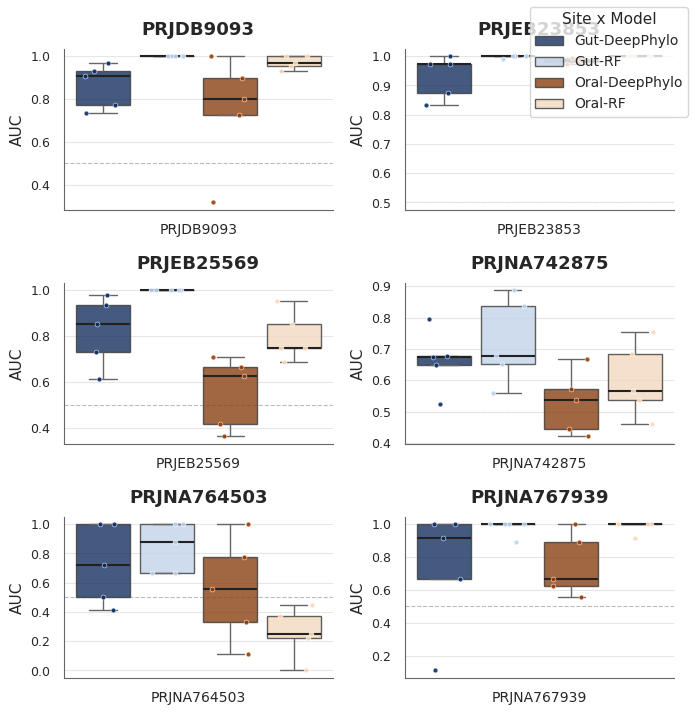

In [415]:
"""
Five-fold CV, paired Oral vs Gut samples: DeepPhylo vs Random Forest.

PART 1 builds df_all_dp / df_all_rf in memory from the raw prediction files:
    run_info_oral_gut.csv                      -> site / fold / study
    result/predictions_deepphylo_<site>_<study>_<fold>.csv  -> DeepPhylo (Prob_1)
    result/RF_results_five_fold.csv            -> RF (pred_prob), group=<site>_<study>_<fold>
    meta_oral_gut.tsv                          -> TRUE case/control labels

One AUC is computed per (site, study, fold, model); the 5 folds form the box.
PART 2 is the provided per-panel plotting code, unchanged, faceted by study.
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build df_all_dp / df_all_rf
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_oral_gut.csv"        # columns: site, fold, study
RESULT_DIR = "result"
RF_FILE    = os.path.join(RESULT_DIR, "RF_results_five_fold.csv")

# ---- Ground-truth labels ----------------------------------------------------
# Both DeepPhylo (SampleID) and RF (sampel_id) use DRR... ids, so one lookup
# keyed by the metadata sample-id column serves both.
META_PATH      = "meta_oral_gut.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID / sampel_id
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = meta[META_LABEL_COL]
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


def _fold_str(v) -> str:
    """Fold as a bare integer string ('1'), tolerant of int/float/str input."""
    try:
        return str(int(v))
    except (ValueError, TypeError):
        return str(v).strip()


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]   # site / fold / study
labels = load_labels()

# ---- DeepPhylo: one prediction file per (site, study, fold) -----------------
dp_records = []
for _, r in run_info.iterrows():
    site, study, fold = str(r["site"]).strip(), str(r["study"]).strip(), _fold_str(r["fold"])
    path = os.path.join(
        RESULT_DIR, f"predictions_deepphylo_{site}_{study}_{fold}.csv"
    )
    if not os.path.exists(path):
        print(f"[DeepPhylo] missing, skipped: {path}")
        continue
    pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
    y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
    y_true = labels.reindex(y_score.index)
    dp_records.append(
        {"site": site, "study": study, "fold": fold,
         "disease": study, "auc": safe_auc(y_true, y_score)}
    )
df_all_dp = pd.DataFrame(dp_records)

# ---- Random Forest: a single file, split by the `group` column --------------
# group == "<site>_<study>_<fold>". Rebuilt from run_info rather than split.
rf_raw = pd.read_csv(RF_FILE)                        # sampel_id, group, pred_prob
rf_raw["group"] = rf_raw["group"].astype(str)

rf_records = []
for _, r in run_info.iterrows():
    site, study, fold = str(r["site"]).strip(), str(r["study"]).strip(), _fold_str(r["fold"])
    group = f"{site}_{study}_{fold}"
    sub = rf_raw[rf_raw["group"] == group]
    if sub.empty:
        print(f"[RF] no rows for group, skipped: {group}")
        continue
    y_score = sub.set_index(sub["sampel_id"].astype(str))["pred_prob"]
    y_true = labels.reindex(y_score.index)
    rf_records.append(
        {"site": site, "study": study, "fold": fold,
         "disease": study, "auc": safe_auc(y_true, y_score)}
    )
df_all_rf = pd.DataFrame(rf_records)

# Drop rows where AUC could not be computed (single-class / no-label folds).
df_all_dp = df_all_dp.dropna(subset=["auc"]).reset_index(drop=True)
df_all_rf = df_all_rf.dropna(subset=["auc"]).reset_index(drop=True)

assert not df_all_dp.empty or not df_all_rf.empty, (
    "No AUC values were computed. Check META_ID_COL / META_LABEL_COL and that "
    "sample ids in the prediction files match the metadata."
)
print(f"[built] DeepPhylo rows={len(df_all_dp)}, RF rows={len(df_all_rf)}")


# =============================================================================
# PART 2 -- provided plotting code (unchanged), fed by df_all_dp / df_all_rf
# =============================================================================

# Per-disease panels comparing DeepPhylo vs RF.
# x = study, boxes grouped by (site x model):
#     hue color  -> site  (Gut / Oral)
#     hue shade  -> model (DeepPhylo = dark, RF = light)

# -- INPUT --
dp = df_all_dp.copy(); dp["model"] = "DeepPhylo"
rf = df_all_rf.copy(); rf["model"] = "RF"
combined = pd.concat([dp, rf], ignore_index=True)
combined["site_model"] = combined["site"] + "-" + combined["model"]

# -- Global style --
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":     "DejaVu Sans",
    "axes.titlesize":  13, "axes.titleweight": "bold",
    "axes.labelsize":  11, "axes.edgecolor":   "#666666",
    "axes.linewidth":  0.8,
    "grid.color":      "#E6E6E6", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize":  9,
})

hue_order = ["Gut-DeepPhylo", "Gut-RF", "Oral-DeepPhylo", "Oral-RF"]
palette = {
    "Gut-DeepPhylo":  "#0B2D6B",
    "Gut-RF":         "#BBD4F0",
    "Oral-DeepPhylo": "#9C3D00",
    "Oral-RF":        "#FBD9B5",
}

# -- Spacing parameters --
BOX_WIDTH = 0.55
BOX_GAP   = 0.15
N_HUES    = len(hue_order)
SLOT_W    = BOX_WIDTH / N_HUES          # width allocated per hue group
# jitter half-range: points fill ~70% of the actual box face (after gap)
HALF_JIT  = SLOT_W * (1 - BOX_GAP) * 0.35

diseases = combined["disease"].unique()
n = len(diseases); ncols = 2; nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 3.5, nrows * 2.4),
                         squeeze=False)
axes = axes.flatten()

handles, labels = None, None
rng = np.random.default_rng(seed=0)   # fixed seed for reproducible jitter

for i, disease in enumerate(diseases):
    ax = axes[i]
    sub = combined[combined["disease"] == disease]

    # Explicit study order so boxplot and scatter share the same x mapping
    study_order = list(sub["study"].unique())
    study_to_x  = {s: j for j, s in enumerate(study_order)}

    # -- Box plot --
    sns.boxplot(
        data=sub, x="study", y="auc",
        hue="site_model", hue_order=hue_order,
        order=study_order,          # anchor x-axis order
        ax=ax,
        width=BOX_WIDTH,
        gap=BOX_GAP,
        showfliers=False,
        palette=palette,
        linewidth=1.0,
        boxprops=dict(alpha=0.8, edgecolor="#3a3a3a"),
        medianprops=dict(color="#222222", linewidth=1.5),
        whiskerprops=dict(color="#666666", linewidth=1.0),
        capprops=dict(color="#666666", linewidth=1.0),
    )

    # -- Manual scatter: positions computed from the same geometry as boxplot --
    # Box centers: x_tick + (-BOX_WIDTH/2 + (h + 0.5) * SLOT_W)
    # gap only shrinks box width; it does NOT shift the center, so no gap term here
    for h_idx, hue_key in enumerate(hue_order):
        pts = sub[sub["site_model"] == hue_key]
        if pts.empty:
            continue
        x_center = -BOX_WIDTH / 2 + (h_idx + 0.5) * SLOT_W
        x_pos = (pts["study"].map(study_to_x).values.astype(float)
                 + x_center
                 + rng.uniform(-HALF_JIT, HALF_JIT, len(pts)))
        ax.scatter(x_pos, pts["auc"].values,
                   color=palette[hue_key],
                   s=3.5 ** 2, alpha=0.9,
                   edgecolors="white", linewidths=0.4,
                   zorder=3)

    ax.set_title(str(disease), pad=10)
    ax.set_xlabel(""); ax.set_ylabel("AUC")
    ax.grid(axis="x", visible=False)
    ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.8, zorder=0)
    sns.despine(ax=ax)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# -- Shared legend --
for j in range(n, len(axes)):
    axes[j].axis("off")

if n < len(axes):
    axes[n].legend(handles, labels, title="Site x Model", loc="center",
                   frameon=True, fontsize=11, title_fontsize=12, markerscale=1.3)
else:
    fig.legend(handles, labels, title="Site x Model", loc="upper right",
               frameon=True, fontsize=10, title_fontsize=11)

fig.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "fivefold_oral_gut_deepphylo_vs_rf.png"),
            dpi=200, bbox_inches="tight")
plt.show()

# Part 3 within-continent and leave-one-continent-out

## Generating Cross-Study Train/Test Splits for Oral Microbiome Classification

This step builds the train/test `.biom` tables used to evaluate disease classifiers on oral microbiome data, along with a manifest describing every split. It loops over four oral sampling sites (**saliva, tooth, tongue, oral mucosa**) and, for each site, produces splits under two evaluation schemes.

### 1. Base filtering
For each site, the sample metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`),
- come from the current sampling site, and
- have a known continent/region (`continent_group`).

### 2. Study-level requirements
- **HC + disease requirement:** A study (`bioproject_id`) is kept only if it contains both healthy controls (`HC`) *and* at least one disease group. This ensures every study can support a case–control comparison.
- **One study → one continent:** Each study is assigned to a single continent (the one holding the majority of its samples), so no individual study is ever split across continents.
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples** to be usable.

### 3. Per-disease split construction
For every disease (excluding `HC`), the code identifies *valid studies* — those where, within a single bioproject, both `HC` and that disease each have >5 samples. A disease is only processed if it has **at least 2 valid studies**. Two complementary splitting schemes are then applied:

**(A) Within-continent, leave-one-study-out (`wc`)**
Within each continent that has ≥2 studies, one study is held out as the **test set** while the remaining studies in that same continent form the **training set**. This measures generalization to a *new study within a familiar region*.

**(B) Leave-one-continent-out (`loco`)**
If the disease spans ≥2 continents, one entire continent is held out as the **test set** and all studies from the other continents are used for **training**. This measures generalization to an *entirely unseen geographic region*.

### 4. Feature-table handling and output
For each split, the corresponding samples are pulled from the `biom` feature table. The training table is emptied of all-zero features, and the test table is restricted to the same feature set as training (so both share identical features). Each split is written to disk as `train_*.biom` / `test_*.biom` with a descriptive filename encoding the site, disease, continent, and held-out study.

### 5. Run manifest
Finally, all splits are collected into a `runs` DataFrame recording the **site, disease, continent, held-out test study, and split type** (`wc` or `loco`). This manifest drives the downstream model-training loop.

In [416]:
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
sid = metadata.sample_id.values
table.filter(sid, axis="sample")
table.remove_empty()
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

In [375]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']

# ---- Confirm the column name representing continent/region in metadata ----
CONTINENT_COL = "continent_group"      # If this column is missing, see the "region column" note below

# run manifest
run_site, run_disease, run_continent, run_test_study, run_split_type = [], [], [], [], []

def clean(x):
    return str(x).replace(' ', '_')

for site in oral_sites:
    print(f"\n########## SITE: {site} ##########")

    # ---------- Base filtering identical to your LSO code ----------
    metadata = pd.read_csv(
        "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv",
        sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]
    metadata = metadata.loc[metadata[CONTINENT_COL].notna()]       # continent must be known
    if metadata.empty:
        continue

    # study must contain HC + at least one disease
    status_per_proj = metadata.groupby("bioproject_id")["status_cleaned"].apply(set)
    cond_both = status_per_proj.apply(lambda s: ("HC" in s) and (len(s - {"HC"}) > 0))
    metadata = metadata.loc[metadata.bioproject_id.isin(status_per_proj.index[cond_both])].copy()
    if metadata.empty:
        continue

    # Assign each study to one continent (the one with the most samples, so a study is never split)
    proj2cont = metadata.groupby("bioproject_id")[CONTINENT_COL].agg(
        lambda s: s.value_counts().index[0])

    # Each (bioproject, status) needs > 5 samples
    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    result = result.query('sample_id > 5')

    for s in result.status_cleaned.unique():
        if s == "HC":
            continue
        print(f"\n=== Disease: {s} ===")

        # Valid studies for this disease: within one bioproject, HC and s each > 5
        result_pick = result[result['status_cleaned'].isin(["HC", s])]
        two = result_pick.groupby('bioproject_id')['status_cleaned'].nunique()
        valid_proj = two[two == 2].index.tolist()
        if len(valid_proj) < 2:
            print(f"  Only {len(valid_proj)} valid study/studies, skipping")
            continue

        # Keep only HC and s samples (to match original code exactly, drop the status_cleaned condition)
        meta_s = metadata[metadata.bioproject_id.isin(valid_proj) &
                          metadata.status_cleaned.isin(["HC", s])]

        proj_cont  = {p: proj2cont[p] for p in valid_proj}
        conts      = sorted(set(proj_cont.values()))
        cont2projs = {c: [p for p in valid_proj if proj_cont[p] == c] for c in conts}
        print("  studies per continent: " +
              ", ".join(f"{c}:{len(v)}" for c, v in cont2projs.items()))

        # ===== (A) within-continent: leave-one-study-out inside each continent =====
        for c, projs in cont2projs.items():
            if len(projs) < 2:                       # need >=2 studies in the continent
                continue
            print(f"  [within] {c}: {len(projs)} studies")
            for j in projs:
                train_study = [p for p in projs if p != j]
                train_sid = meta_s[meta_s.bioproject_id.isin(train_study)]['sample_id'].values
                test_sid  = meta_s[meta_s.bioproject_id == j]['sample_id'].values

                train_biom = table.filter(train_sid, axis="sample", inplace=False)
                train_biom.remove_empty()
                fid = train_biom.ids(axis="observation")
                test_biom = table.filter(test_sid, axis="sample", inplace=False)
                test_biom.filter(fid, axis="observation")
                print(f"    test={j}  train {train_biom.shape}  test {test_biom.shape}")

                base = f"wc_{clean(site)}_{clean(s)}_{clean(c)}_{j}"
                with biom.util.biom_open(f"data/train_{base}.biom", 'w') as f:
                    train_biom.to_hdf5(f, 'example')
                with biom.util.biom_open(f"data/test_{base}.biom", 'w') as f:
                    test_biom.to_hdf5(f, 'example')

                run_site.append(clean(site)); run_disease.append(clean(s))
                run_continent.append(clean(c)); run_test_study.append(str(j))
                run_split_type.append("wc")

        # ===== (B) leave-one-continent-out: disease must span >=2 continents =====
        if len(conts) < 2:
            print("  Spans only 1 continent, skipping leave-one-continent-out")
            continue
        for c in conts:
            test_projs  = cont2projs[c]
            train_projs = [p for p in valid_proj if proj_cont[p] != c]
            test_sid  = meta_s[meta_s.bioproject_id.isin(test_projs)]['sample_id'].values
            train_sid = meta_s[meta_s.bioproject_id.isin(train_projs)]['sample_id'].values

            train_biom = table.filter(train_sid, axis="sample", inplace=False)
            train_biom.remove_empty()
            fid = train_biom.ids(axis="observation")
            test_biom = table.filter(test_sid, axis="sample", inplace=False)
            test_biom.filter(fid, axis="observation")
            print(f"  [LOCO] test-continent={c}: "
                  f"train {len(train_projs)} studies {train_biom.shape}, "
                  f"test {len(test_projs)} studies {test_biom.shape}")

            base = f"loco_{clean(site)}_{clean(s)}_{clean(c)}"
            with biom.util.biom_open(f"data/train_{base}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/test_{base}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')

            run_site.append(clean(site)); run_disease.append(clean(s))
            run_continent.append(clean(c)); run_test_study.append("ALL")
            run_split_type.append("loco")

# Collect all splits for the downstream training loop
runs = pd.DataFrame({
    "site": run_site, "disease": run_disease, "continent": run_continent,
    "test_study": run_test_study, "split_type": run_split_type,
})


########## SITE: saliva ##########

=== Disease: Gastroesophageal Reflux Disease ===
  studies per continent: Asia:2, North America:1
  [within] Asia: 2 studies
    test=PRJCA005537  train (593, 67)  test (593, 192)
    test=PRJNA639327  train (1224, 192)  test (1224, 67)
  [LOCO] test-continent=Asia: train 1 studies (494, 125), test 2 studies (494, 259)
  [LOCO] test-continent=North America: train 2 studies (1333, 259), test 1 studies (1333, 125)

=== Disease: Hypertension ===
  studies per continent: Asia:2
  [within] Asia: 2 studies
    test=PRJCA006963  train (715, 57)  test (715, 45)
    test=PRJNA764503  train (788, 45)  test (788, 57)
  Spans only 1 continent, skipping leave-one-continent-out

=== Disease: IBD ===
  studies per continent: Asia:2, Europe:1, North America:1
  [within] Asia: 2 studies
    test=PRJCA006963  train (470, 20)  test (470, 69)
    test=PRJNA544600  train (834, 69)  test (834, 20)
  [LOCO] test-continent=Asia: train 2 studies (942, 228), test 2 studies (

In [376]:
runs.to_csv("run_info_continent.csv", index=False)

/home/dongbiao/tmp/ipykernel_287247/1300681289.py:65: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[DeepPhylo] missing, skipped: result/predictions_deepphylo_loco_oral_mucosa_Aphthous_Asia.csv
[built] 68 AUC rows (wc=34, loco=34)


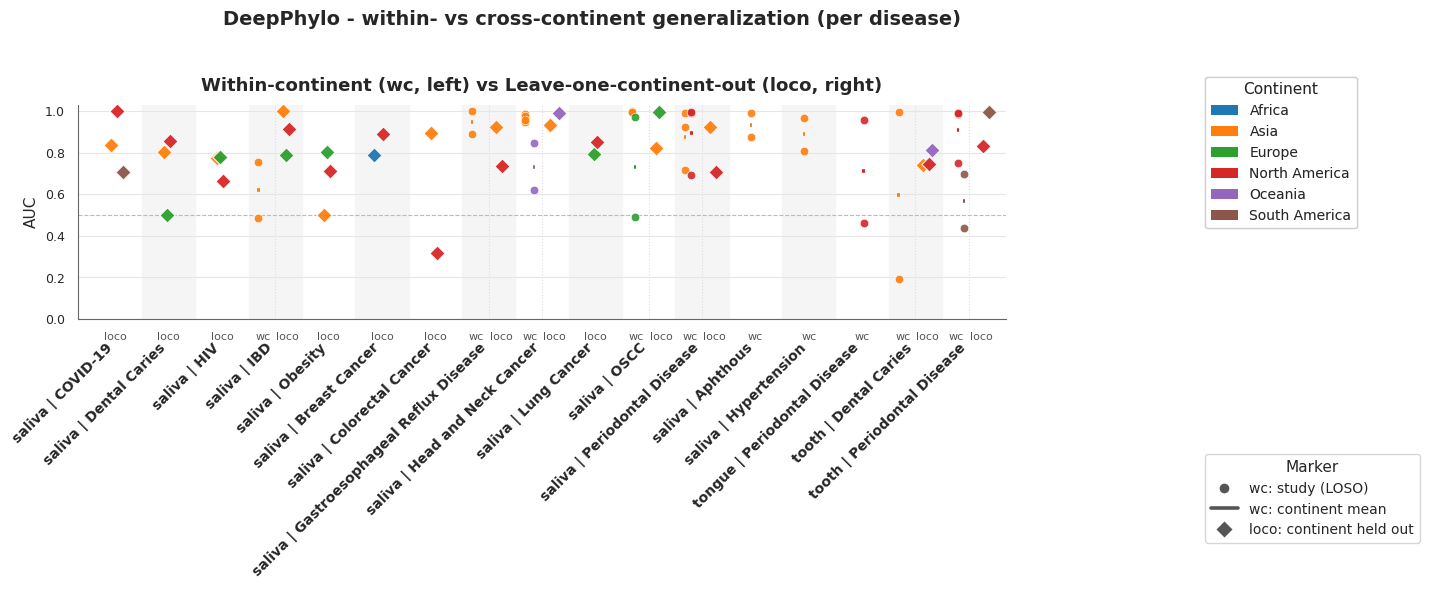

In [453]:
"""
DeepPhylo -- within-continent (wc, analysis A) vs leave-one-continent-out
(loco, analysis B), drawn in ONE panel for easy comparison.

*** Layout ***
Single panel. Each disease occupies one x slot:
  - both wc and loco present : wc (dots + mean bar) on the LEFT sub-cluster,
                               loco (diamonds) on the RIGHT, dotted divider between.
  - wc only  : draw wc centred at the slot (no empty loco half reserved).
  - loco only: draw loco centred at the slot.
Continent colours are consistent and horizontally aligned across wc/loco, so the
within-continent vs cross-continent generalization can be compared per disease.
X axis: small wc/loco sub-labels, then the disease name rotated 45 degrees.

PART 1 (unchanged) builds one AUC per run_info row from the prediction files:
    run_info_continent.csv
        columns: site, disease, continent, test_study, split_type
    result/predictions_deepphylo_wc_<site>_<disease>_<continent>_<test_study>.csv
    result/predictions_deepphylo_loco_<site>_<disease>_<continent>.csv
    meta.tsv  -> TRUE case/control labels (SampleID = SRR...)
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table   (unchanged)
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_continent.csv"    # site, disease, continent, test_study, split_type
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (SRR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)

SPLIT_LABEL = {"wc": "Within-continent", "loco": "Cross-continent"}


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

records = []
for _, r in run_info.iterrows():
    split = str(r["split_type"]).strip()
    site = str(r["site"]).strip()
    disease = str(r["disease"]).strip()
    continent = str(r["continent"]).strip()
    study = str(r["test_study"]).strip()

    # wc  : ..._<continent>_<test_study>.csv
    # loco: ..._<continent>.csv        (whole continent held out, no study suffix)
    stem = f"predictions_deepphylo_{split}_{site}_{disease}_{continent}"
    if split == "loco" or study.upper() == "ALL":
        candidates = [f"{stem}.csv", f"{stem}_{study}.csv"]
    else:
        candidates = [f"{stem}_{study}.csv"]
    path = next((os.path.join(RESULT_DIR, c)
                 for c in candidates
                 if os.path.exists(os.path.join(RESULT_DIR, c))), None)
    if path is None:
        print(f"[DeepPhylo] missing, skipped: {os.path.join(RESULT_DIR, candidates[0])}")
        continue

    pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
    y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
    y_true = labels.reindex(y_score.index)
    records.append({
        "site": site, "disease": disease, "continent": continent,
        "test_study": study, "split_type": split,
        "split": SPLIT_LABEL.get(split, split),
        "auc": safe_auc(y_true, y_score),
    })

df = pd.DataFrame(records).dropna(subset=["auc"]).reset_index(drop=True)
df = df.loc[df.site != "oral_mucosa"]
assert not df.empty, (
    "No AUC values were computed. Check META_ID_COL / META_LABEL_COL and that "
    "SampleIDs in the prediction files match the metadata."
)
print(f"[built] {len(df)} AUC rows "
      f"(wc={ (df.split_type=='wc').sum() }, loco={ (df.split_type=='loco').sum() })")


# =============================================================================
# PART 2 -- single panel: wc (left) / loco (right) side by side;
#           centre the lone side when only one split exists; x labels at 45 deg
# =============================================================================

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":     "DejaVu Sans",
    "axes.titlesize":  13, "axes.titleweight": "bold",
    "axes.labelsize":  11, "axes.edgecolor":   "#666666",
    "axes.linewidth":  0.8,
    "grid.color":      "#E6E6E6", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize":  9,
})

# x categories: disease (prefixed with site only if more than one site present)
multi_site = df["site"].nunique() > 1
df["xcat"] = (df["site"] + " | " + df["disease"]) if multi_site else df["disease"]

# order: when multi_site, group diseases of the same site together;
# otherwise sort by number of continents covered, then name
if multi_site:
    all_xcats = sorted(
        df["xcat"].unique(),
        key=lambda x: (df[df.xcat == x]["site"].iloc[0],
                       -df[df.xcat == x]["continent"].nunique(), x),
    )
else:
    all_xcats = sorted(
        df["xcat"].unique(),
        key=lambda x: (-df[df.xcat == x]["continent"].nunique(), x),
    )
pos = {x: i for i, x in enumerate(all_xcats)}

# which splits each disease actually has (may be wc-only or loco-only)
present = {x: set(df[df.xcat == x]["split_type"]) for x in all_xcats}

# consistent continent colours + within-cluster horizontal dodge
continents = sorted(df["continent"].unique())
K = len(continents)
pal = sns.color_palette("tab10", n_colors=max(K, 3))
cont_color = {c: pal[i] for i, c in enumerate(continents)}

HALF    = 0.23                              # when both: wc=pos-HALF, loco=pos+HALF
SUBSTEP = min(0.34 / max(K, 1), 0.12)       # per-continent dodge step inside a sub-cluster
cont_dodge = {c: (i - (K - 1) / 2) * SUBSTEP for i, c in enumerate(continents)}
MEAN_HALFWIDTH = SUBSTEP * 0.42


def sub_centers(x):
    """Return wc / loco sub-cluster centre x (lone side is centred on the slot)."""
    i = pos[x]
    both = present[x] == {"wc", "loco"}
    wc_c = (i - HALF) if both else i
    loco_c = (i + HALF) if both else i
    return wc_c, loco_c


ncols = len(all_xcats)
fig, ax = plt.subplots(figsize=(12, 6))

# alternating background per disease; wc|loco divider only when both are present
for x, i in pos.items():
    if i % 2 == 1:
        ax.axvspan(i - 0.5, i + 0.5, color="#F5F5F5", zorder=0)
    if present[x] == {"wc", "loco"}:
        ax.axvline(i, color="#DDDDDD", ls=":", lw=0.8, zorder=0)

for x in all_xcats:
    sub = df[df["xcat"] == x]
    wc_c, loco_c = sub_centers(x)
    for cont in continents:
        col = cont_color[cont]
        d = cont_dodge[cont]

        # ---- wc: one LOSO dot per study + continent-mean bar ----
        if "wc" in present[x]:
            wc_vals = sub[(sub.continent == cont) & (sub.split_type == "wc")]["auc"].values
            if len(wc_vals):
                xw = wc_c + d
                ax.scatter(np.full(len(wc_vals), xw), wc_vals,
                           marker="o", s=38, facecolors=col, edgecolors="white",
                           linewidths=0.5, alpha=0.9, zorder=3)
                ax.hlines(wc_vals.mean(), xw - MEAN_HALFWIDTH, xw + MEAN_HALFWIDTH,
                          colors=col, linewidths=2.6, zorder=4)

        # ---- loco: one diamond per held-out continent ----
        if "loco" in present[x]:
            lc_vals = sub[(sub.continent == cont) & (sub.split_type == "loco")]["auc"].values
            if len(lc_vals):
                xl = loco_c + d
                ax.scatter(np.full(len(lc_vals), xl), lc_vals,
                           marker="D", s=60, facecolors=col, edgecolors="white",
                           linewidths=0.8, alpha=0.95, zorder=4)

ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.8, zorder=1)
ax.set_ylim(0, 1.03)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("AUC")
ax.set_xlim(-0.7, ncols - 0.3)

# ---- two-level x labels: wc/loco sub-labels (adaptive), then 45-deg disease name ----
sub_ticks, sub_labels = [], []
for x in all_xcats:
    wc_c, loco_c = sub_centers(x)
    if present[x] == {"wc", "loco"}:
        sub_ticks += [wc_c, loco_c]
        sub_labels += ["wc", "loco"]
    elif "wc" in present[x]:
        sub_ticks.append(wc_c)
        sub_labels.append("wc")
    else:
        sub_ticks.append(loco_c)
        sub_labels.append("loco")
ax.set_xticks(sub_ticks)
ax.set_xticklabels(sub_labels, fontsize=8, color="#555555")

trans = ax.get_xaxis_transform()            # x=data, y=axes-fraction
for x, i in pos.items():
    ax.text(i, -0.10, x.replace("_", " "), transform=trans,
            ha="right", va="top", rotation=45, fontsize=10, fontweight="bold")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

# ---- legend: continents (colour) + marker meaning ---------------------------
cont_handles = [Patch(facecolor=cont_color[c], edgecolor="none",
                      label=c.replace("_", " ")) for c in continents]
marker_handles = [
    mlines.Line2D([], [], color="#555555", marker="o", linestyle="None",
                  markersize=8, markeredgecolor="white", label="wc: study (LOSO)"),
    mlines.Line2D([], [], color="#555555", linestyle="-", linewidth=2.6,
                  label="wc: continent mean"),
    mlines.Line2D([], [], color="#555555", marker="D", linestyle="None",
                  markersize=9, markeredgecolor="white", label="loco: continent held out"),
]
leg1 = fig.legend(handles=cont_handles, title="Continent",
                  loc="upper left", bbox_to_anchor=(1.005, 0.92),
                  frameon=True, fontsize=10, title_fontsize=11)
fig.add_artist(leg1)
fig.legend(handles=marker_handles, title="Marker",
           loc="lower left", bbox_to_anchor=(1.005, 0.12),
           frameon=True, fontsize=10, title_fontsize=11)

ax.set_title("Within-continent (wc, left) vs Leave-one-continent-out (loco, right)",
             pad=10)
fig.suptitle("DeepPhylo - within- vs cross-continent generalization (per disease)",
             fontsize=14, fontweight="bold", y=1.02)

fig.tight_layout(rect=[0, 0, 0.86, 1.0])
plt.savefig(os.path.join(RESULT_DIR, "continent_A_vs_B_combined.png"),
            dpi=200, bbox_inches="tight")
plt.show()

### Part 4 : Cross-disease: training disease A, testing disease B

## Generating Cross-Disease Transfer Train/Test Splits (Within Site)

This step builds train/test `.biom` tables for evaluating **cross-disease transfer** — training a classifier on one oral disease and testing whether it generalizes to a *different* disease. It loops over three oral sampling sites (**saliva, tooth, tongue**) and, within each site, creates one split for every ordered pair of usable diseases. A run manifest describing all splits is produced at the end.

### 1. Target diseases
A fixed list of oral diseases is defined for the transfer analysis (`ORAL_DISEASES`), including conditions such as Dental Caries, OSCC, Periodontal Disease, Oral Submucous Fibrosis, Oral Mucositis, Oral Verrucous Hyperplasia, Aphthous, Oral Lichen Planus, and Head and Neck Cancer. This list can be edited to include or exclude conditions (e.g., dropping Head and Neck Cancer for a strictly-oral analysis).

### 2. Base filtering (per site)
For each site, the metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`), and
- come from the current sampling site.

### 3. Identifying usable diseases
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples**, computed *after* the site filter.
- **Valid studies per disease:** For a given disease, a study is "valid" only if, within that single bioproject, both `HC` and that disease each have >5 samples at this site.
- A disease is marked **usable** at this site if it has at least one valid study.
- If fewer than **2 usable diseases** exist at a site, no cross-disease pair can be formed and the site is skipped.

### 4. Building disease sample sets
For each usable disease, the sample set consists of `HC` + that disease, restricted to the disease's valid studies within the current site. This becomes the pool from which train and test sets are drawn.

### 5. Cross-disease pairing (all ordered pairs)
For every ordered pair of usable diseases **(A → B)** where A ≠ B:
- **Train** = `HC + A` samples; **Test** = `HC + B` samples.
- **Leakage guard:** Any sample appearing in both train and test (which can happen when a study contributes HC to both diseases at the same site) is removed from the test set. If no test samples remain afterward, the pair is skipped.
- The feature tables are pulled from the `biom` table; the training table is emptied of all-zero features, and the test table is restricted to the same feature set so both share identical features.
- Each split is written to disk as `train_*.biom` / `test_*.biom`, with a filename encoding the site and the train/test disease pair (`cd_{site}_train_{A}_test_{B}`).

### 6. Run manifest
All splits are collected into a `runs_cd` DataFrame recording, for each pair: the **site**, **train disease**, **test disease**, total train/test sample counts (`n_train`, `n_test`), the number of case (non-HC) samples in each (`n_train_case`, `n_test_case`), and a fixed `split_type` of `cross_disease_within_site`. This manifest drives the downstream model-training loop.

In [377]:
oral_sites = ['saliva', 'tooth', 'tongue']

# Typical oral diseases for cross-disease transfer (edit as needed)
ORAL_DISEASES = [
    'Dental Caries', 'OSCC', 'Periodontal Disease',
    'Oral Submucous Fibrosis', 'Oral Mucositis',
    'Oral Verrucous Hyperplasia', 'Aphthous', 'Oral Lichen Planus',
    'Head and Neck Cancer',   # includes oral cavity; remove if you want strictly-oral
]

def clean(x):
    return str(x).replace(' ', '_')

# run manifest (now includes site)
run_site, run_train, run_test = [], [], []
run_ntrain, run_ntest, run_ntrain_case, run_ntest_case = [], [], [], []

for site in oral_sites:
    print(f"\n########## SITE: {site} ##########")

    # ---------- Base filtering, same criteria, now per site ----------
    metadata = pd.read_csv(
        "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv",
        sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]     # restrict to this site
    if metadata.empty:
        print("  no samples at this site, skipping")
        continue

    # Each (bioproject, status) needs > 5 samples -- computed AFTER the site filter
    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    result = result.query('sample_id > 5')

    # For each disease, keep only studies where BOTH HC and that disease have > 5 samples at this site
    def valid_studies_for(d):
        pick = result[result['status_cleaned'].isin(["HC", d])]
        two = pick.groupby('bioproject_id')['status_cleaned'].nunique()
        return two[two == 2].index.tolist()

    usable = {}
    for d in ORAL_DISEASES:
        projs = valid_studies_for(d)
        if len(projs) >= 1:
            usable[d] = projs

    if len(usable) < 2:
        print(f"  only {len(usable)} usable disease(s) at this site, "
              f"cannot form a cross-disease pair, skipping")
        continue

    print("  usable diseases: " +
          ", ".join(f"{d}({len(p)} studies)" for d, p in usable.items()))

    # Samples (HC + d) restricted to d's valid studies, within this site
    def disease_samples(d):
        m = metadata[metadata.bioproject_id.isin(usable[d]) &
                     metadata.status_cleaned.isin(["HC", d])]
        return m

    # ---------- Cross-disease: all ordered pairs (train on A, test on B) ----------
    diseases = list(usable.keys())
    for A in diseases:
        mA = disease_samples(A)
        train_sid = mA['sample_id'].values
        for B in diseases:
            if A == B:
                continue
            mB = disease_samples(B)
            test_sid = mB['sample_id'].values

            # Guard against leakage: drop any test sample also present in train
            # (only if a study contributes HC to both A and B at this site)
            overlap = set(train_sid) & set(test_sid)
            if overlap:
                print(f"  [warn] {A}->{B}: {len(overlap)} shared samples removed from test")
                test_sid = np.array([x for x in test_sid if x not in overlap])
            if len(test_sid) == 0:
                print(f"  [skip] {A}->{B}: no test samples left")
                continue

            # Build biom tables and align features to the training set
            train_biom = table.filter(train_sid, axis="sample", inplace=False)
            train_biom.remove_empty()
            fid = train_biom.ids(axis="observation")
            test_biom = table.filter(test_sid, axis="sample", inplace=False)
            test_biom.filter(fid, axis="observation")

            n_train_case = int((mA.status_cleaned == A).sum())
            n_test_case  = int((metadata[metadata.sample_id.isin(test_sid)]
                                .status_cleaned == B).sum())

            print(f"  [cross-disease] train={A} (HC+{A}, {train_biom.shape})  "
                  f"test={B} (HC+{B}, {test_biom.shape})")

            base = f"cd_{clean(site)}_train_{clean(A)}_test_{clean(B)}"
            with biom.util.biom_open(f"data/train_{base}.biom", 'w') as f:
                train_biom.to_hdf5(f, 'example')
            with biom.util.biom_open(f"data/test{base}.biom", 'w') as f:
                test_biom.to_hdf5(f, 'example')

            run_site.append(clean(site))
            run_train.append(clean(A)); run_test.append(clean(B))
            run_ntrain.append(train_biom.shape[1]); run_ntest.append(test_biom.shape[1])
            run_ntrain_case.append(n_train_case); run_ntest_case.append(n_test_case)

# Collect all cross-disease splits for the downstream training loop
runs_cd = pd.DataFrame({
    "site": run_site,
    "train_disease": run_train, "test_disease": run_test,
    "n_train": run_ntrain, "n_test": run_ntest,
    "n_train_case": run_ntrain_case, "n_test_case": run_ntest_case,
    "split_type": "cross_disease_within_site",
})


########## SITE: saliva ##########
  usable diseases: Dental Caries(3 studies), OSCC(5 studies), Periodontal Disease(6 studies), Oral Mucositis(1 studies), Oral Verrucous Hyperplasia(1 studies), Aphthous(2 studies), Oral Lichen Planus(1 studies), Head and Neck Cancer(6 studies)
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=OSCC (HC+OSCC, (1063, 468))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=Periodontal Disease (HC+Periodontal Disease, (1063, 699))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=Oral Mucositis (HC+Oral Mucositis, (1063, 175))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=Oral Verrucous Hyperplasia (HC+Oral Verrucous Hyperplasia, (1063, 48))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=Aphthous (HC+Aphthous, (1063, 84))
  [cross-disease] train=Dental Caries (HC+Dental Caries, (1063, 113))  test=Oral Lichen Planus (HC+O

In [378]:
runs_cd.head()

,site,train_disease,test_disease,n_train,n_test,n_train_case,n_test_case,split_type
0,saliva,Dental_Caries,OSCC,113,468,51,235,cross_disease_within_site
1,saliva,Dental_Caries,Periodontal_Disease,113,699,51,390,cross_disease_within_site
2,saliva,Dental_Caries,Oral_Mucositis,113,175,51,128,cross_disease_within_site
3,saliva,Dental_Caries,Oral_Verrucous_Hyperplasia,113,48,51,21,cross_disease_within_site
4,saliva,Dental_Caries,Aphthous,113,84,51,51,cross_disease_within_site


In [379]:
runs_cd.to_csv("run_info_cross_disease.csv", index=False)

/home/dongbiao/tmp/ipykernel_287247/251952085.py:57: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[built] 60 train->test pairs (59 with a valid AUC)


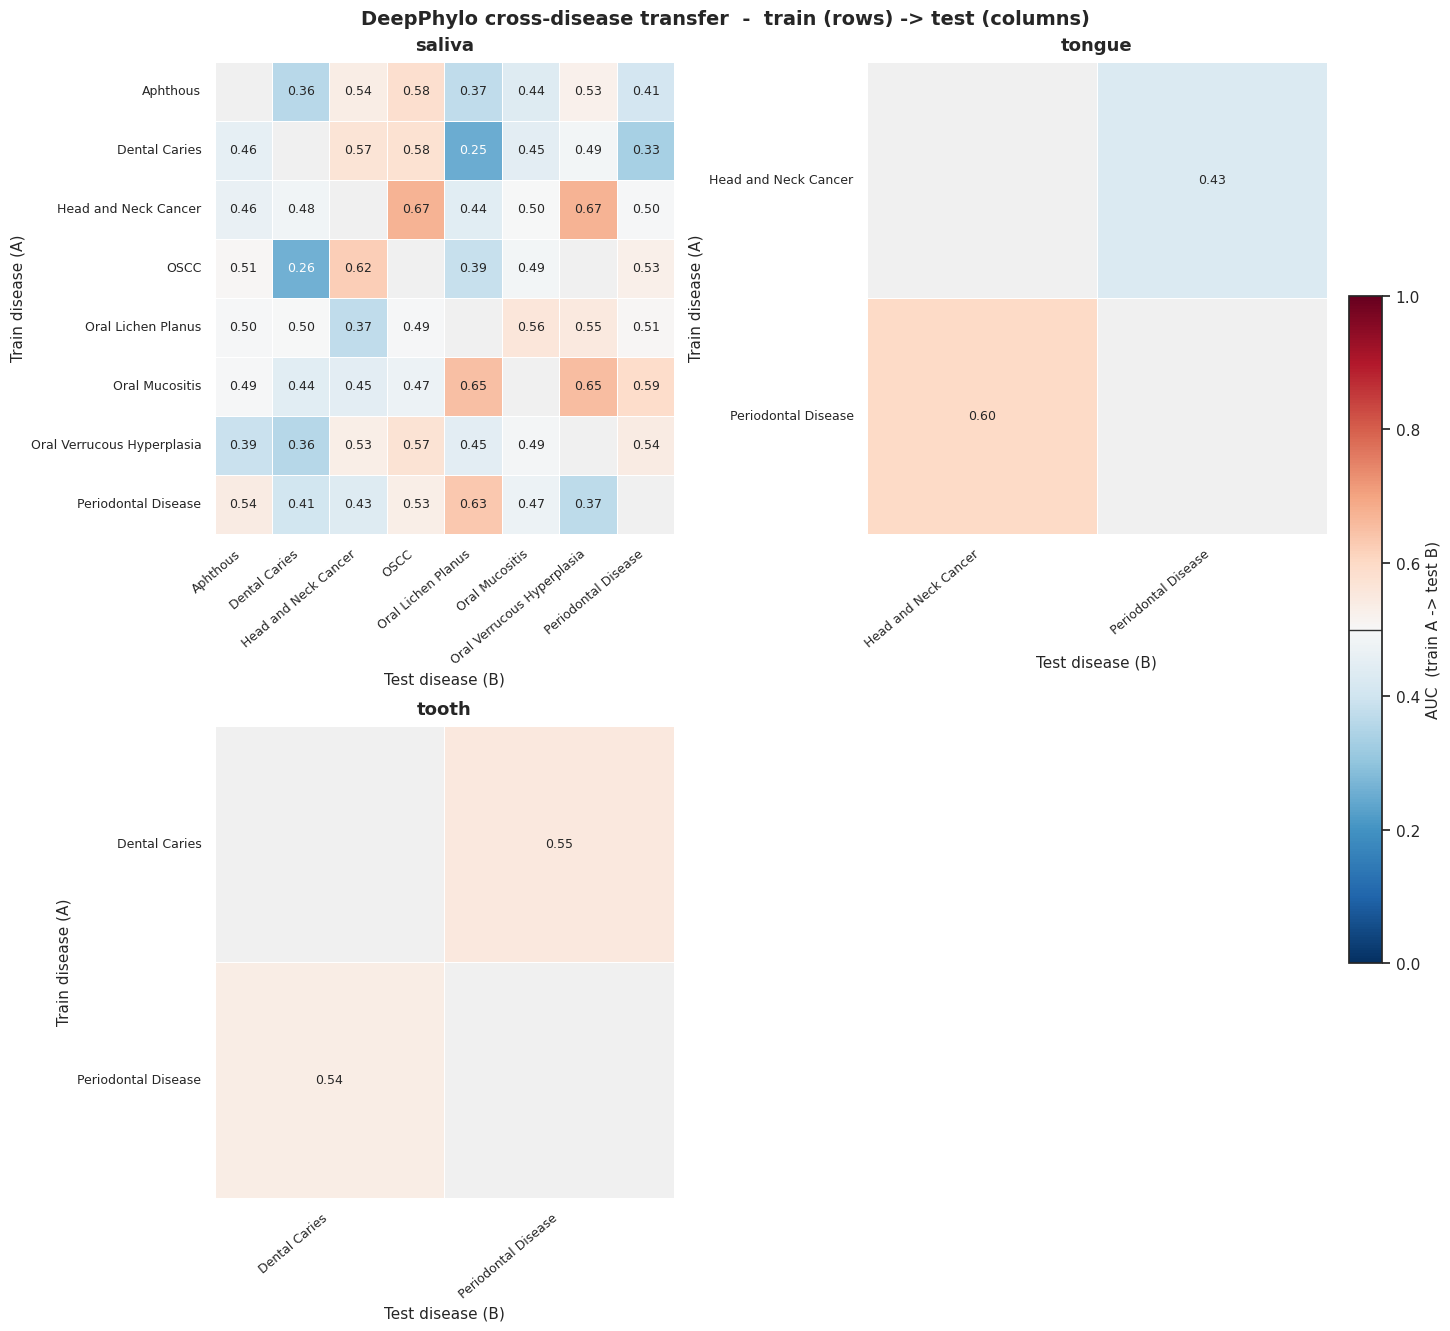

In [454]:
"""
DeepPhylo cross-disease transfer: train on disease A, test on disease B
(all ordered pairs, within each site).

PART 1 -- one AUC per run_info row from the prediction files:
    run_info_cross_disease.csv
        columns include: site, train_disease, test_disease, split_type
    result/predictions_deepphylo_cd_<site>_train_<train_disease>_test_<test_disease>.csv
    meta.tsv  -> TRUE case/control labels (SampleID = ERR...)

PART 2 -- one transfer-matrix heatmap per site:
    rows    = train disease (A)   -- only diseases that actually have results
    columns = test disease  (B)   -- only diseases that actually have results
    colour  = AUC (RdBu_r, 0.5 = white = chance; red better, blue worse)
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_cross_disease.csv"
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (ERR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

records = []
for _, r in run_info.iterrows():
    site = str(r["site"]).strip()
    train = str(r["train_disease"]).strip()
    test = str(r["test_disease"]).strip()
    path = os.path.join(
        RESULT_DIR,
        f"predictions_deepphylo_cd_{site}_train_{train}_test_{test}.csv",
    )
    if not os.path.exists(path):
        print(f"[DeepPhylo] missing, skipped: {path}")
        continue
    pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
    y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
    y_true = labels.reindex(y_score.index)
    records.append({
        "site": site, "train_disease": train, "test_disease": test,
        "auc": safe_auc(y_true, y_score),
    })

df = pd.DataFrame(records)
assert not df.empty, (
    "No rows built. Check RESULT_DIR / file naming and META_ID_COL / META_LABEL_COL."
)
n_ok = df["auc"].notna().sum()
print(f"[built] {len(df)} train->test pairs ({n_ok} with a valid AUC)")

df.to_csv(os.path.join(RESULT_DIR, "cross_disease_auc_long.csv"), index=False)


# =============================================================================
# PART 2 -- transfer-matrix heatmap(s), one per site
# =============================================================================

sns.set_theme(style="white", context="notebook")
mpl.rcParams.update({
    "font.family":    "DejaVu Sans",
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

CMAP, VMIN, VMAX = "RdBu_r", 0.0, 1.0   # 0.5 -> white (chance)

valid = df[df["auc"].notna()]
sites = sorted(valid["site"].unique())

n = len(sites)
ncols = min(n, 2)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 7.2, nrows * 6.6),
                         squeeze=False, constrained_layout=True)
axes = axes.flatten()

for i, site in enumerate(sites):
    ax = axes[i]
    sub = valid[valid["site"] == site]

    # keep only diseases that really appear for this site (drop all-empty rows/cols)
    rows = sorted(sub["train_disease"].unique())
    cols = sorted(sub["test_disease"].unique())
    mat = (sub.pivot_table(index="train_disease", columns="test_disease", values="auc")
              .reindex(index=rows, columns=cols))

    sns.heatmap(
        mat, ax=ax, cmap=CMAP, vmin=VMIN, vmax=VMAX,
        annot=True, fmt=".2f", annot_kws={"size": 9},
        linewidths=0.6, linecolor="white",
        mask=mat.isna(), cbar=False, square=False,
    )
    ax.set_facecolor("#F0F0F0")                     # missing pairs within this site
    ax.set_title(site, pad=8)
    ax.set_xlabel("Test disease (B)")
    ax.set_ylabel("Train disease (A)")
    ax.set_xticklabels([t.get_text().replace("_", " ") for t in ax.get_xticklabels()],
                       rotation=40, ha="right", fontsize=9)
    ax.set_yticklabels([t.get_text().replace("_", " ") for t in ax.get_yticklabels()],
                       rotation=0, fontsize=9)

for j in range(n, len(axes)):
    axes[j].axis("off")

# Shared colour bar
sm = ScalarMappable(norm=Normalize(VMIN, VMAX), cmap=CMAP)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), fraction=0.03, pad=0.02, shrink=0.85)
cbar.set_label("AUC  (train A -> test B)")
cbar.ax.axhline(0.5, color="#333333", lw=1.0)       # mark the chance level

fig.suptitle("DeepPhylo cross-disease transfer  -  train (rows) -> test (columns)",
             fontsize=14, fontweight="bold")
plt.savefig(os.path.join(RESULT_DIR, "cross_disease_transfer.png"),
            dpi=200, bbox_inches="tight")
plt.show()

### Part 5 Learning Curve: training sample size

## Generating Learning-Curve Train/Test Splits

This step builds train/test `.biom` tables for constructing **learning curves** — measuring how classifier performance changes as the number of training studies grows. It runs on a small set of hand-picked, large-sample `(site, disease)` combinations, and for each one it sweeps the number of studies used in training from 2 up to the maximum available. A run manifest describing all splits is produced at the end.

### 1. Configuration
- **`SEED = 42`** fixes the random seed for reproducible study sampling.
- **`N_REPEAT = 3`** sets how many distinct study subsets to draw at each subset size.
- **`LC_TARGETS`** lists the specific `(site, disease)` combinations to analyze — chosen because they have enough samples to support a meaningful curve (e.g., saliva/OSCC, saliva/Head and Neck Cancer, saliva/Periodontal Disease, tooth/Periodontal Disease).

### 2. Distinct-subset sampling helper
`draw_distinct_subsets` returns up to `n_want` distinct k-sized subsets of the available studies. To stay efficient across both small and large pools, it uses two strategies:
- **Small pools** (≤200 possible combinations): enumerate all k-subsets, shuffle, and take the first `n`.
- **Large pools:** rejection-sample random subsets until `n` distinct ones are collected.

This ensures the repeats at each subset size are genuinely different combinations of studies.

### 3. Base filtering (per target)
For each `(site, disease)` target, the metadata is loaded and filtered to keep only samples that:
- have a known, non-`"Other"` disease status (`status_cleaned`),
- appear in the working sample-ID set (`sid`), and
- come from the current site.

### 4. Identifying valid studies
- **Minimum group size:** Each `(study, status)` group must have **more than 5 samples**.
- **Valid studies:** A study (`bioproject_id`) counts only if, within that single bioproject, both `HC` and the target disease each have >5 samples.
- The number of valid studies sets the maximum subset size (`max_k`). If fewer than **2 studies** qualify, no learning curve can be built and the target is skipped.
- Sampling is then restricted to `HC + disease` samples within these valid studies.

### 5. Learning-curve construction
For each subset size **k = 2 … max_k**:
- Draw up to `N_REPEAT` distinct k-study subsets (the "repeats").
- Within each sampled subset, apply **leave-one-study-out**: each study `j` in the subset is held out as the **test set** in turn, while the remaining k−1 studies form the **training set**.
- For every train/test split, the feature tables are pulled from the `biom` table; the training table is emptied of all-zero features, and the test table is restricted to the same feature set so both share identical features.
- Each split is written to disk as `train_*.biom` / `test_*.biom`, with a filename encoding the site, disease, subset size, repeat index, and held-out study (`lc_{site}_{disease}_k{k}_r{rep}_test_{j}`).

### 6. Run manifest
All splits are collected into a `runs_lc` DataFrame recording, for each split: the **site**, **disease**, number of training-pool studies (`n_studies` = k), **repeat** index, the full **subset** of studies used (pipe-joined), the held-out **test study**, and a fixed `split_type` of `learning_curve`. This manifest drives the downstream model-training loop, where results are aggregated across repeats and held-out studies to trace performance as a function of study count.

In [381]:
SEED = 42
N_REPEAT = 3

# One analysis per (site, disease): large-sample combos only
LC_TARGETS = [
    ("saliva", "OSCC"),
    ("saliva", "Head and Neck Cancer"),
    ("saliva", "Periodontal Disease"),
    ("tooth",  "Periodontal Disease"),
]

def clean(x):
    return str(x).replace(' ', '_')

def draw_distinct_subsets(items, k, n_want, rng):
    """Return up to n_want distinct k-subsets of items (as sorted tuples)."""
    total = comb(len(items), k)
    n = min(n_want, total)
    if total <= 200:                      # small: enumerate then sample
        allc = list(combinations(sorted(items), k))
        rng.shuffle(allc)
        return allc[:n]
    seen = set()                          # large: rejection-sample
    while len(seen) < n:
        seen.add(tuple(sorted(rng.sample(items, k))))
    return list(seen)

# run manifest
run_site, run_disease, run_k, run_rep, run_subset, run_test = [], [], [], [], [], []

for site, disease in LC_TARGETS:
    print(f"\n########## SITE: {site} | DISEASE: {disease} ##########")

    # ---------- Base filtering, same criteria as before ----------
    metadata = pd.read_csv(
        "../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv",
        sep="\t", low_memory=False)
    metadata = metadata.loc[metadata.status_cleaned.notna()]
    metadata = metadata.loc[metadata.status_cleaned != "Other"]
    metadata = metadata.loc[[i in sid for i in metadata.sample_id]]
    metadata = metadata.loc[metadata.site_cleaned == site]

    # Each (bioproject, status) needs > 5 samples
    result = metadata.groupby(["bioproject_id", "status_cleaned"])['sample_id'].count().reset_index()
    result = result.query('sample_id > 5')

    # Valid studies: within one bioproject, HC and disease each > 5
    pick = result[result['status_cleaned'].isin(["HC", disease])]
    two = pick.groupby('bioproject_id')['status_cleaned'].nunique()
    valid_proj = two[two == 2].index.tolist()
    max_k = len(valid_proj)
    print(f"  valid studies: {max_k} -> {valid_proj}")
    if max_k < 2:
        print("  fewer than 2 studies, cannot build a learning curve, skipping")
        continue

    # Restrict to HC + disease samples within valid studies
    meta_d = metadata[metadata.bioproject_id.isin(valid_proj) &
                      metadata.status_cleaned.isin(["HC", disease])]

    rng = random.Random(SEED)

    # ---------- Learning curve: k = 2 .. max_k ----------
    for k in range(2, max_k + 1):
        subsets = draw_distinct_subsets(valid_proj, k, N_REPEAT, rng)
        print(f"  k={k}: {len(subsets)} repeat(s)")
        for rep, subset in enumerate(subsets):
            subset = list(subset)
            # leave-one-study-out inside the sampled k studies
            for j in subset:
                train_study = [p for p in subset if p != j]
                train_sid = meta_d[meta_d.bioproject_id.isin(train_study)]['sample_id'].values
                test_sid  = meta_d[meta_d.bioproject_id == j]['sample_id'].values

                train_biom = table.filter(train_sid, axis="sample", inplace=False)
                train_biom.remove_empty()
                fid = train_biom.ids(axis="observation")
                test_biom = table.filter(test_sid, axis="sample", inplace=False)
                test_biom.filter(fid, axis="observation")

                base = f"lc_{clean(site)}_{clean(disease)}_k{k}_r{rep}_test_{j}"
                with biom.util.biom_open(f"data/train_{base}.biom", 'w') as f:
                    train_biom.to_hdf5(f, 'example')
                with biom.util.biom_open(f"data/test_{base}.biom", 'w') as f:
                    test_biom.to_hdf5(f, 'example')

                run_site.append(clean(site)); run_disease.append(clean(disease))
                run_k.append(k); run_rep.append(rep)
                run_subset.append("|".join(str(p) for p in subset))
                run_test.append(str(j))

            print(f"    r{rep}: studies={subset}")

# Collect all learning-curve splits for the downstream training loop
runs_lc = pd.DataFrame({
    "site": run_site, "disease": run_disease,
    "n_studies": run_k, "repeat": run_rep,
    "subset": run_subset, "test_study": run_test,
    "split_type": "learning_curve",
})


########## SITE: saliva | DISEASE: OSCC ##########
  valid studies: 5 -> ['PRJEB18476', 'PRJEB39064', 'PRJNA386665', 'PRJNA756784', 'PRJNA997108']
  k=2: 3 repeat(s)
    r0: studies=['PRJNA386665', 'PRJNA756784']
    r1: studies=['PRJEB18476', 'PRJNA997108']
    r2: studies=['PRJEB18476', 'PRJNA756784']
  k=3: 3 repeat(s)
    r0: studies=['PRJEB18476', 'PRJNA386665', 'PRJNA756784']
    r1: studies=['PRJEB18476', 'PRJNA756784', 'PRJNA997108']
    r2: studies=['PRJEB18476', 'PRJEB39064', 'PRJNA997108']
  k=4: 3 repeat(s)
    r0: studies=['PRJEB18476', 'PRJEB39064', 'PRJNA386665', 'PRJNA756784']
    r1: studies=['PRJEB18476', 'PRJNA386665', 'PRJNA756784', 'PRJNA997108']
    r2: studies=['PRJEB18476', 'PRJEB39064', 'PRJNA756784', 'PRJNA997108']
  k=5: 1 repeat(s)
    r0: studies=['PRJEB18476', 'PRJEB39064', 'PRJNA386665', 'PRJNA756784', 'PRJNA997108']

########## SITE: saliva | DISEASE: Head and Neck Cancer ##########
  valid studies: 6 -> ['PRJEB37445', 'PRJNA421234', 'PRJNA666972', 'PRJ

In [383]:
runs_lc.head()

,site,disease,n_studies,repeat,subset,test_study,split_type
0,saliva,OSCC,2,0,PRJNA386665|PRJNA756784,PRJNA386665,learning_curve
1,saliva,OSCC,2,0,PRJNA386665|PRJNA756784,PRJNA756784,learning_curve
2,saliva,OSCC,2,1,PRJEB18476|PRJNA997108,PRJEB18476,learning_curve
3,saliva,OSCC,2,1,PRJEB18476|PRJNA997108,PRJNA997108,learning_curve
4,saliva,OSCC,2,2,PRJEB18476|PRJNA756784,PRJEB18476,learning_curve


In [384]:
runs_lc.to_csv("run_info_lc.csv", index=False)

/home/dongbiao/tmp/ipykernel_287247/2146504029.py:58: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH, sep=sep)


[DeepPhylo] missing, skipped: result/predictions_deepphylo_lc_saliva_Head_and_Neck_Cancer_k4_r0_test_PRJNA421234.csv
[DeepPhylo] missing, skipped: result/predictions_deepphylo_lc_saliva_Head_and_Neck_Cancer_k4_r2_test_PRJEB37445.csv
[DeepPhylo] missing, skipped: result/predictions_deepphylo_lc_saliva_Head_and_Neck_Cancer_k5_r1_test_PRJNA901226.csv
[built] 157 rows; sizes = [2, 3, 4, 5, 6]


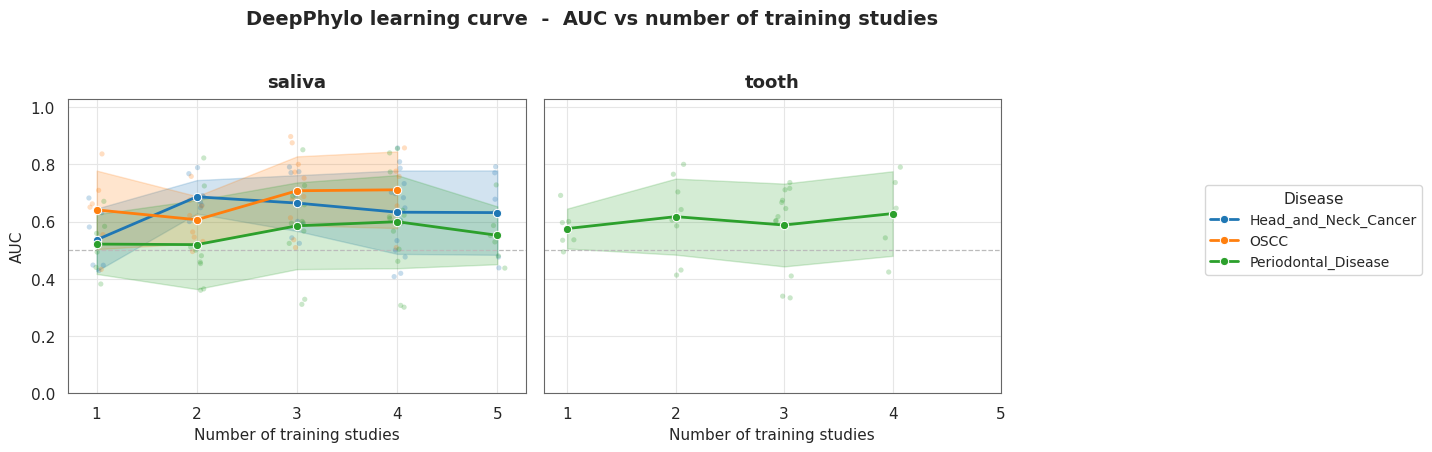

In [444]:
"""
DeepPhylo learning curve: effect of dataset size (number of training studies)
on performance.

PART 1 -- one AUC per run_info row from the prediction files:
    run_info_lc.csv
        columns: site, disease, n_studies, repeat, subset, test_study, split_type
    result/predictions_deepphylo_lc_<site>_<disease>_k<n_studies>_r<repeat>_test_<test_study>.csv
    meta.tsv  -> TRUE case/control labels (SampleID = SRR...)

PART 2 -- AUC vs number of training studies:
    line   = mean AUC per disease at each dataset size
    band   = spread across repeats and held-out studies (std dev)
    dots   = individual (repeat, test_study) AUCs (faint)
    one panel per site.
"""

import math
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# =============================================================================
# PART 1 -- build the AUC table
# =============================================================================

# ------------------------------------------------------------------ CONFIG ---
RUN_INFO   = "run_info_lc.csv"
RESULT_DIR = "result"

# ---- Ground-truth labels ----------------------------------------------------
META_PATH      = "meta.tsv"
META_ID_COL    = "sample_id"   # sample id column; must match SampleID (SRR...)
META_LABEL_COL = "group"       # binary target column (case=1 / control=0)

ERRORBAR = "sd"   # band: "sd" (std dev), "se" (std error), or ("ci", 95)


def _to_binary(s: pd.Series) -> pd.Series:
    """Coerce a label column to 0/1 floats, accepting common string encodings."""
    if s.dtype != object:
        return pd.to_numeric(s, errors="coerce")
    mapping = {
        "case": 1, "control": 0, "disease": 1, "healthy": 0, "patient": 1,
        "positive": 1, "negative": 0, "yes": 1, "no": 0,
        "true": 1, "false": 0, "1": 1, "0": 0,
    }
    return s.astype(str).str.strip().str.lower().map(mapping)


def load_labels() -> pd.Series:
    """Return a Series: sample_id -> binary label (0/1)."""
    sep = "\t" if META_PATH.lower().endswith((".tsv", ".txt")) else ","
    meta = pd.read_csv(META_PATH, sep=sep)
    missing = [c for c in (META_ID_COL, META_LABEL_COL) if c not in meta.columns]
    if missing:
        raise KeyError(
            f"{missing} not found in {META_PATH}. "
            f"Available columns: {list(meta.columns)}"
        )
    labels = _to_binary(meta[META_LABEL_COL])
    labels.index = meta[META_ID_COL].astype(str)
    return labels[~labels.index.duplicated(keep="first")]


def safe_auc(y_true: pd.Series, y_score: pd.Series) -> float:
    """AUC that returns NaN instead of raising on degenerate inputs."""
    df = pd.DataFrame({"y": y_true.values, "s": y_score.values}).dropna()
    if len(df) < 2 or df["y"].nunique() < 2:
        return np.nan
    return roc_auc_score(df["y"], df["s"])


def _int(v) -> str:
    try:
        return str(int(v))
    except (ValueError, TypeError):
        return str(v).strip()


# ---- Load inputs ------------------------------------------------------------
run_info = pd.read_csv(RUN_INFO)
run_info.columns = [c.strip().lower() for c in run_info.columns]
labels = load_labels()

records = []
for _, r in run_info.iterrows():
    site = str(r["site"]).strip()
    disease = str(r["disease"]).strip()
    k = _int(r["n_studies"])
    rep = _int(r["repeat"])
    test = str(r["test_study"]).strip()

    path = os.path.join(
        RESULT_DIR,
        f"predictions_deepphylo_lc_{site}_{disease}_k{k}_r{rep}_test_{test}.csv",
    )
    if not os.path.exists(path):
        print(f"[DeepPhylo] missing, skipped: {path}")
        continue
    pred = pd.read_csv(path)                        # SampleID, Prob_1, Pred
    y_score = pred.set_index(pred["SampleID"].astype(str))["Prob_1"]
    y_true = labels.reindex(y_score.index)
    records.append({
        "site": site, "disease": disease,
        "n_studies": int(k),                 # pool size (incl. held-out test study)
        "n_train_studies": int(k) - 1,       # studies actually used for training
        "repeat": int(rep), "test_study": test,
        "auc": safe_auc(y_true, y_score),
    })

df = pd.DataFrame(records).dropna(subset=["auc"]).reset_index(drop=True)
assert not df.empty, (
    "No AUC values were computed. Check file naming and META_ID_COL / META_LABEL_COL."
)
print(f"[built] {len(df)} rows; sizes = {sorted(df['n_studies'].unique())}")
df.to_csv(os.path.join(RESULT_DIR, "learning_curve_auc_long.csv"), index=False)


# =============================================================================
# PART 2 -- learning-curve plot
# =============================================================================

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "font.family":    "DejaVu Sans",
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.edgecolor": "#666666", "axes.linewidth": 0.8,
    "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
})

diseases = sorted(df["disease"].unique())
pal = dict(zip(diseases, sns.color_palette("tab10", n_colors=max(len(diseases), 3))))
sites = sorted(df["site"].unique())
xticks = sorted(df["n_train_studies"].unique())

n = len(sites)
ncols = min(n, 2)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 6.0, nrows * 4.6),
                         squeeze=False, sharey=True)
axes = axes.flatten()

rng = np.random.default_rng(0)
handles_labels = None

for i, site in enumerate(sites):
    ax = axes[i]
    d = df[df["site"] == site]

    # faint raw points (small horizontal jitter so repeats don't stack)
    for dis in diseases:
        s = d[d["disease"] == dis]
        if s.empty:
            continue
        jit = rng.uniform(-0.08, 0.08, len(s))
        ax.scatter(s["n_train_studies"] + jit, s["auc"], color=pal[dis],
                   s=14, alpha=0.25, edgecolors="none", zorder=2)

    # mean line + spread band per disease
    sns.lineplot(
        data=d, x="n_train_studies", y="auc", hue="disease", hue_order=diseases,
        palette=pal, estimator="mean", errorbar=ERRORBAR,
        marker="o", markersize=6, linewidth=2.0, err_style="band",
        ax=ax, legend=(i == 0), zorder=3,
    )

    ax.axhline(0.5, color="#BBBBBB", ls="--", lw=0.9, zorder=1)
    ax.set_title(site, pad=8)
    ax.set_xlabel("Number of training studies")
    ax.set_ylabel("AUC")
    ax.set_ylim(0, 1.03)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xticks(xticks)

    if i == 0 and ax.get_legend() is not None:
        handles_labels = ax.get_legend_handles_labels()
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for j in range(n, len(axes)):
    axes[j].axis("off")

if handles_labels is not None:
    fig.legend(*handles_labels, title="Disease", loc="center left",
               bbox_to_anchor=(1.005, 0.5), frameon=True,
               fontsize=10, title_fontsize=11)

fig.suptitle("DeepPhylo learning curve  -  AUC vs number of training studies",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 0.86, 0.96])
plt.savefig(os.path.join(RESULT_DIR, "learning_curve.png"),
            dpi=200, bbox_inches="tight")
plt.show()